# Section 1: Notebook Overview

**Scheduling Method:** Baselines and Heuristics

**Responsible Member:** Aroob

**Objective:** Implement and evaluate five non-learning scheduling methods using the frozen BEE shared package and the common experimental protocol.

**Research Question:** How strong are non-learning scheduling rules compared with reinforcement learning-based scheduling methods?

**Methods:**
1. Random Feasible
2. Earliest Window-End First
3. Shortest Requested Duration First
4. Least-Flexible First
5. Weighted Composite Heuristic

**Expected Outputs:** Validated schedules, configuration-selection results, cross-week evaluation results, summary tables, figures and a report-ready interpretation.

# Section 2: Environment Setup

 Mount Google Drive

In [1]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


Locate Shared Package

In [2]:
from pathlib import Path
import sys

PACKAGE_ROOT = Path("/content/drive/MyDrive/BEE/shared_v2")
SRC_DIR = PACKAGE_ROOT / "src"

assert PACKAGE_ROOT.exists(), f"shared_v2 was not found at: {PACKAGE_ROOT}"
assert SRC_DIR.exists(), f"Source folder was not found at: {SRC_DIR}"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

print("Shared package loaded from:", PACKAGE_ROOT)

Shared package loaded from: /content/drive/MyDrive/BEE/shared_v2


Import Shared Configuration and Data

In [3]:
from experiment_config import (
    PACKAGE_VERSION,
    CANONICAL_SPLIT,
    ROBUSTNESS_FOLDS,
    TRAINING_SEEDS,
    EVALUATION_SEEDS,
    MAX_REQUESTS,
    MAX_STEPS,
    TOTAL_TIMESTEPS,
    CHECKPOINT_FREQUENCY,
    PPO_CONFIG,
    RESULT_COLUMNS,
    SUMMARY_METRICS,
)

from experiment_utils import (
    load_shared_data,
    select_weeks,
    make_base_environment,
    mask_function,
    validate_environment_schedule,
    evaluate_maskable_policy,
)

request_table, visibility_table, maintenance_table = load_shared_data(PACKAGE_ROOT)

print("Package version:", PACKAGE_VERSION)
print("Requests:", request_table.shape)
print("Visibility periods:", visibility_table.shape)
print("Maintenance intervals:", maintenance_table.shape)
print("Weeks:", sorted(request_table["week_key"].unique()))

Package version: shared_v2
Requests: (1452, 21)
Visibility periods: (14699, 17)
Maintenance intervals: (1798, 6)
Weeks: ['W10_2018', 'W20_2018', 'W30_2018', 'W40_2018', 'W50_2018']


# Section 3: Load Shared Project Package

Verify Shared Package Manifest

In [4]:
import json

manifest_path = PACKAGE_ROOT / "metadata" / "package_manifest.json"

with open(manifest_path, "r") as file:
    manifest = json.load(file)

assert PACKAGE_VERSION == "shared_v2"
assert manifest["package_version"] == "shared_v2"

print("Verified package version:", manifest["package_version"])
print(json.dumps(manifest, indent=2))

Verified package version: shared_v2
{
  "package_version": "shared_v2",
  "source": "BEE Phase 3 validated implementation",
  "optimization": {
    "visibility_cache": true,
    "maintenance_cache": true,
    "affected_antenna_refresh": true
  },
  "modules": {
    "environment.py": "bb5cc62f3dd23fff749b8591a7ce2a994abd05b220f66e90fbcb5544d7aebda7",
    "experiment_config.py": "9704cd0c1000ff58fa9afb9eceaf18f995c9f0090c24d3213c2722a0c810269f",
    "experiment_utils.py": "a92190c7a0d02c641b2967886821cfe716220ec8297cc4d3bb59d9e58c0b80c1",
    "placement.py": "6579b898b1c7047ea0ce9b04a55cdaec3ecde9408b694aa326f48c1d4e9fc4fd",
    "validator.py": "b1dcbb306d180fd723b31f078ccb6f1b1817bf7f23d04e49ee181e8b53badcf3"
  }
}


In [5]:
from pathlib import Path

NEW_PACKAGE_ROOT = Path("/content/drive/MyDrive/BEE/shared_v2")

assert NEW_PACKAGE_ROOT.exists(), "shared_v2 not found"
assert (NEW_PACKAGE_ROOT / "src").exists(), "src folder not found"
assert (NEW_PACKAGE_ROOT / "metadata" / "package_manifest.json").exists(), "Manifest not found"

print("shared_v2 found successfully")

shared_v2 found successfully


In [7]:
import json

NEW_MANIFEST_PATH = NEW_PACKAGE_ROOT / "metadata" / "package_manifest.json"

with open(NEW_MANIFEST_PATH, "r") as file:
    new_manifest = json.load(file)

assert new_manifest["package_version"] == "shared_v2"

print("Package verification passed.")
print("Package version:", new_manifest["package_version"])
print("Shared module hashes:")

for filename, file_hash in new_manifest["modules"].items():
    print(f"  {filename}: {file_hash}")

Package verification passed.
Package version: shared_v2
Shared module hashes:
  environment.py: bb5cc62f3dd23fff749b8591a7ce2a994abd05b220f66e90fbcb5544d7aebda7
  experiment_config.py: 9704cd0c1000ff58fa9afb9eceaf18f995c9f0090c24d3213c2722a0c810269f
  experiment_utils.py: a92190c7a0d02c641b2967886821cfe716220ec8297cc4d3bb59d9e58c0b80c1
  placement.py: 6579b898b1c7047ea0ce9b04a55cdaec3ecde9408b694aa326f48c1d4e9fc4fd
  validator.py: b1dcbb306d180fd723b31f078ccb6f1b1817bf7f23d04e49ee181e8b53badcf3


# Section 4: Verify Shared Data

In [6]:
print("Request table shape:", request_table.shape)
print("Visibility table shape:", visibility_table.shape)
print("Maintenance table shape:", maintenance_table.shape)

print("\nRequests per week:")
print(request_table.groupby("week_key").size())

print("\nMissing values in request data:")
print(request_table.isna().sum())

print("\nDuplicate request identifiers:")
print(request_table.duplicated(subset=["week_key", "track_id"]).sum())

assert len(request_table) == 1452
assert request_table["week_key"].nunique() == 5
assert request_table.duplicated(subset=["week_key", "track_id"]).sum() == 0

print("\nBasic data verification passed.")

Request table shape: (1452, 21)
Visibility table shape: (14699, 17)
Maintenance table shape: (1798, 6)

Requests per week:
week_key
W10_2018    257
W20_2018    294
W30_2018    293
W40_2018    333
W50_2018    275
dtype: int64

Missing values in request data:
week_key                        0
week                            0
year                            0
subject                         0
user                            0
track_id                        0
duration_seconds                0
minimum_duration_seconds        0
setup_seconds                   0
teardown_seconds                0
time_window_start               0
time_window_end                 0
number_of_resource_options      0
number_of_physical_antennas     0
number_of_visibility_periods    0
total_visible_seconds           0
resource_options                0
duration_flexibility_ratio      0
placement_scarcity_raw          0
resource_scarcity_raw           0
static_resource_contention      0
dtype: int64

Duplicate requ

# Section 5: Method Implementation

The five methods are Random Feasible, Earliest Window-End First, Shortest Requested Duration First, Least-Flexible First and Weighted Composite Heuristic. All methods use the frozen shared placement logic and action constraints.

Inspect Shared Environment Interface

In [7]:
import inspect
print("Environment factory:")
print(inspect.signature(make_base_environment))

print("\nMask function:")
print(inspect.signature(mask_function))

print("\nEnvironment source:")
print(inspect.getsource(make_base_environment))

Environment factory:
(requests, visibility, maintenance, seed=42, shuffle_requests=True)

Mask function:
(environment)

Environment source:
def make_base_environment(requests, visibility, maintenance, seed=42, shuffle_requests=True):
    return BEEGroundStationEnv(
        requests=requests.copy(),
        visibility_periods=visibility.copy(),
        maintenance=maintenance.copy(),
        include_bee_features=False,
        seed=seed,
        max_requests=MAX_REQUESTS,
        max_steps=MAX_STEPS,
        shuffle_requests=shuffle_requests,
    )



Inspect Environment Methods

In [8]:
from environment import BEEGroundStationEnv

print("Reset:")
print(inspect.signature(BEEGroundStationEnv.reset))

print("\nStep:")
print(inspect.signature(BEEGroundStationEnv.step))

print("\nAction masks:")
print(inspect.getsource(BEEGroundStationEnv.action_masks))

Reset:
(self, seed=None, options=None)

Step:
(self, action)

Action masks:
    def action_masks(self):
        return self._action_mask.copy()



Inspect Environment State

In [9]:
test_env = make_base_environment(
    request_table,
    visibility_table,
    maintenance_table,
    seed=42,
    shuffle_requests=False,
)

observation, info = test_env.reset()

print("Environment attributes:")
print(sorted(vars(test_env).keys()))

print("\nObservation type:", type(observation))
print("Observation shape:", getattr(observation, "shape", None))
print("Reset info:", info)

print("\nAction space:", test_env.action_space)
print("Available actions:", int(test_env.action_masks().sum()))

Environment attributes:
['_action_mask', '_actions_by_antenna', '_candidate_cache', '_maintenance_by_antenna', '_rng', '_visibility_by_track', 'action_space', 'all_maintenance', 'all_requests', 'all_visibility', 'current_week_key', 'global_feature_count', 'include_bee_features', 'initial_seed', 'maintenance', 'max_requests', 'max_steps', 'observation_space', 'occupancy', 'request_feature_count', 'requests', 'schedule', 'scheduled_actions', 'shuffle_requests', 'step_count', 'subject_allocated_seconds', 'subject_requested_seconds', 'total_minimum_seconds', 'total_requested_seconds', 'visibility', 'week_keys']

Observation type: <class 'numpy.ndarray'>
Observation shape: (3001,)
Reset info: {'week_key': 'W10_2018', 'number_of_requests': 257, 'valid_actions': 257}

Action space: Discrete(333)
Available actions: 257


Inspect Request Ordering and Action Mapping

In [10]:
print("Requests type:", type(test_env.requests))
print("Requests shape:", test_env.requests.shape)
print("\nRequest columns:")
print(test_env.requests.columns.tolist())

print("\nFirst five requests:")
print(
    test_env.requests[
        [
            "week_key",
            "track_id",
            "duration_seconds",
            "time_window_end",
            "number_of_resource_options",
            "placement_scarcity_raw",
        ]
    ].head()
)

print("\nFirst ten available action indices:")
print(test_env.action_masks().nonzero()[0][:10])

Requests type: <class 'pandas.core.frame.DataFrame'>
Requests shape: (257, 21)

Request columns:
['week_key', 'week', 'year', 'subject', 'user', 'track_id', 'duration_seconds', 'minimum_duration_seconds', 'setup_seconds', 'teardown_seconds', 'time_window_start', 'time_window_end', 'number_of_resource_options', 'number_of_physical_antennas', 'number_of_visibility_periods', 'total_visible_seconds', 'resource_options', 'duration_flexibility_ratio', 'placement_scarcity_raw', 'resource_scarcity_raw', 'static_resource_contention']

First five requests:
   week_key      track_id  duration_seconds  time_window_end  \
0  W10_2018  00ca891d-7-1             14400       1520325462   
1  W10_2018  00ca891d-7-2             14400       1520411035   
2  W10_2018  00ca891d-7-3             14400       1520496608   
3  W10_2018  00ca891d-7-4             14400       1520582180   
4  W10_2018  00ca891d-7-5             14400       1520667753   

   number_of_resource_options  placement_scarcity_raw  
0     

Verify Action-to-Request Mapping

In [11]:
print(inspect.getsource(BEEGroundStationEnv.step))

    def step(self, action):
        action = int(action)
        self.step_count += 1

        valid_action = (
            0 <= action < self.max_requests
            and bool(self._action_mask[action])
        )

        if not valid_action:
            reward = -1.0

            terminated = bool(
                self._action_mask.sum() == 0
            )

            truncated = bool(
                self.step_count >= self.max_steps
            )

            observation = self._get_observation()

            info = {
                "valid_action": False,
                "week_key": self.current_week_key,
                "action": action,
            }

            return (
                observation,
                reward,
                terminated,
                truncated,
                info,
            )

        request = self.requests.iloc[action]

        placement = self._candidate_cache[action][0]
        placement = placement.copy()
        placement["action"] = 

Random Feasible Heuristic

In [12]:
import numpy as np

def random_feasible_action(environment, rng):
    valid_actions = np.flatnonzero(environment.action_masks())

    if len(valid_actions) == 0:
        return None

    return int(rng.choice(valid_actions))

Test Random Feasible Heuristic

In [13]:
test_env.reset(seed=42)

rng = np.random.default_rng(42)
action = random_feasible_action(test_env, rng)

assert action is not None
assert test_env.action_masks()[action]

observation, reward, terminated, truncated, info = test_env.step(action)

assert info["valid_action"] is True

print("Selected action:", action)
print("Track ID:", info["track_id"])
print("Reward:", reward)
print("Scheduled requests:", info["scheduled_requests"])
print("Remaining valid actions:", info["remaining_valid_actions"])

Selected action: 22
Track ID: 07b3f07a-6-2
Reward: 1.5
Scheduled requests: 1
Remaining valid actions: 256


Earliest Window-End First Heuristic

In [14]:
def earliest_window_end_action(environment):
    valid_actions = np.flatnonzero(environment.action_masks())

    if len(valid_actions) == 0:
        return None

    window_ends = environment.requests.iloc[valid_actions]["time_window_end"].to_numpy()

    return int(valid_actions[np.argmin(window_ends)])

Test Earliest Window-End First Heuristic

In [15]:
test_env.reset(seed=42)

action = earliest_window_end_action(test_env)

assert action is not None
assert test_env.action_masks()[action]

valid_actions = np.flatnonzero(test_env.action_masks())
earliest_end = test_env.requests.iloc[valid_actions]["time_window_end"].min()
selected_end = test_env.requests.iloc[action]["time_window_end"]

assert selected_end == earliest_end

observation, reward, terminated, truncated, info = test_env.step(action)

assert info["valid_action"] is True

print("Selected action:", action)
print("Track ID:", info["track_id"])
print("Window end:", selected_end)
print("Reward:", reward)
print("Scheduled requests:", info["scheduled_requests"])
print("Remaining valid actions:", info["remaining_valid_actions"])
print("Earliest Window-End First test passed.")

Selected action: 153
Track ID: 927d0daa-8-1
Window end: 1520284695
Reward: 1.5
Scheduled requests: 1
Remaining valid actions: 256
Earliest Window-End First test passed.


Shortest Requested Duration First Heuristic

In [16]:
def shortest_duration_action(environment):
    valid_actions = np.flatnonzero(environment.action_masks())

    if len(valid_actions) == 0:
        return None

    durations = environment.requests.iloc[valid_actions]["duration_seconds"].to_numpy()

    return int(valid_actions[np.argmin(durations)])

 Test Shortest Requested Duration First Heuristic

In [17]:
test_env.reset(seed=42)

action = shortest_duration_action(test_env)

assert action is not None
assert test_env.action_masks()[action]

valid_actions = np.flatnonzero(test_env.action_masks())
shortest_duration = test_env.requests.iloc[valid_actions]["duration_seconds"].min()
selected_duration = test_env.requests.iloc[action]["duration_seconds"]

assert selected_duration == shortest_duration

observation, reward, terminated, truncated, info = test_env.step(action)

assert info["valid_action"] is True

print("Selected action:", action)
print("Track ID:", info["track_id"])
print("Requested duration (seconds):", selected_duration)
print("Reward:", reward)
print("Scheduled requests:", info["scheduled_requests"])
print("Remaining valid actions:", info["remaining_valid_actions"])
print("Shortest Requested Duration First test passed.")

Selected action: 38
Track ID: 1800fb15-1-1
Requested duration (seconds): 3600
Reward: 1.5
Scheduled requests: 1
Remaining valid actions: 256
Shortest Requested Duration First test passed.


Least-Flexible First Heuristic

In [18]:
def least_flexible_action(environment):
    valid_actions = np.flatnonzero(environment.action_masks())

    if len(valid_actions) == 0:
        return None

    scarcity = environment.requests.iloc[valid_actions]["placement_scarcity_raw"].to_numpy()

    return int(valid_actions[np.argmax(scarcity)])

Test Least-Flexible First Heuristic

In [19]:
test_env.reset(seed=42)

action = least_flexible_action(test_env)

assert action is not None
assert test_env.action_masks()[action]

valid_actions = np.flatnonzero(test_env.action_masks())
highest_scarcity = test_env.requests.iloc[valid_actions]["placement_scarcity_raw"].max()
selected_scarcity = test_env.requests.iloc[action]["placement_scarcity_raw"]

assert np.isclose(selected_scarcity, highest_scarcity)

observation, reward, terminated, truncated, info = test_env.step(action)

assert info["valid_action"] is True

print("Selected action:", action)
print("Track ID:", info["track_id"])
print("Placement scarcity:", selected_scarcity)
print("Reward:", reward)
print("Scheduled requests:", info["scheduled_requests"])
print("Remaining valid actions:", info["remaining_valid_actions"])
print("Least-Flexible First test passed.")

Selected action: 156
Track ID: 927d0daa-8-4
Placement scarcity: 0.9999999900000002
Reward: 1.5
Scheduled requests: 1
Remaining valid actions: 256
Least-Flexible First test passed.


Weighted Composite Heuristic Configurations

In [20]:
COMPOSITE_CONFIGS = {
    "H1": {"a": 0.40, "b": 0.30, "c": 0.20, "d": 0.10},
    "H2": {"a": 0.50, "b": 0.20, "c": 0.20, "d": 0.10},
    "H3": {"a": 0.40, "b": 0.20, "c": 0.30, "d": 0.10},
    "H4": {"a": 0.50, "b": 0.30, "c": 0.20, "d": 0.00},
}

assert all(
    np.isclose(sum(weights.values()), 1.0)
    for weights in COMPOSITE_CONFIGS.values()
)

for name, weights in COMPOSITE_CONFIGS.items():
    print(name, weights)

H1 {'a': 0.4, 'b': 0.3, 'c': 0.2, 'd': 0.1}
H2 {'a': 0.5, 'b': 0.2, 'c': 0.2, 'd': 0.1}
H3 {'a': 0.4, 'b': 0.2, 'c': 0.3, 'd': 0.1}
H4 {'a': 0.5, 'b': 0.3, 'c': 0.2, 'd': 0.0}


Inspect Mission Demand Tracking

In [21]:
test_env.reset(seed=42)

print("Subject requested seconds:")
print(list(test_env.subject_requested_seconds.items())[:5])

print("\nSubject allocated seconds:")
print(list(test_env.subject_allocated_seconds.items())[:5])

print("\nSubject column sample:")
print(test_env.requests["subject"].head())

print("\nDuration range:")
print(test_env.requests["duration_seconds"].agg(["min", "max"]))

Subject requested seconds:
[('164', 7200.0), ('18', 403200.0), ('196', 43200.0), ('211', 201600.0), ('221', 324000.0)]

Subject allocated seconds:
[('164', 0.0), ('18', 0.0), ('196', 0.0), ('211', 0.0), ('221', 0.0)]

Subject column sample:
0    97
1    97
2    97
3    97
4    97
Name: subject, dtype: object

Duration range:
min     3600
max    36000
Name: duration_seconds, dtype: int64


Mission Unmet Demand Calculation

In [22]:
def mission_unmet_demand(environment, subject):
    subject = str(subject)

    requested = environment.subject_requested_seconds.get(subject, 0.0)
    allocated = environment.subject_allocated_seconds.get(subject, 0.0)

    if requested <= 0:
        return 0.0

    return float(np.clip((requested - allocated) / requested, 0.0, 1.0))

Test Mission Unmet Demand

In [23]:
test_env.reset(seed=42)

subject = str(test_env.requests.iloc[0]["subject"])

requested = test_env.subject_requested_seconds[subject]
allocated = test_env.subject_allocated_seconds[subject]

unmet_demand = mission_unmet_demand(test_env, subject)

assert np.isclose(unmet_demand, 1.0)

print("Subject:", subject)
print("Requested seconds:", requested)
print("Allocated seconds:", allocated)
print("Unmet demand:", unmet_demand)
print("Mission Unmet Demand test passed.")

Subject: 97
Requested seconds: 100800.0
Allocated seconds: 0.0
Unmet demand: 1.0
Mission Unmet Demand test passed.


Temporal Urgency Calculation

In [24]:
def temporal_urgency(environment, valid_actions):
    window_ends = environment.requests.iloc[valid_actions]["time_window_end"].to_numpy(dtype=float)

    earliest = window_ends.min()
    latest = window_ends.max()

    if np.isclose(earliest, latest):
        return np.ones(len(valid_actions), dtype=float)

    urgency = (latest - window_ends) / (latest - earliest)

    return np.clip(urgency, 0.0, 1.0)

Test Temporal Urgency

In [25]:
test_env.reset(seed=42)

valid_actions = np.flatnonzero(test_env.action_masks())
urgency_scores = temporal_urgency(test_env, valid_actions)

window_ends = test_env.requests.iloc[valid_actions]["time_window_end"].to_numpy()

assert len(urgency_scores) == len(valid_actions)
assert np.all((urgency_scores >= 0.0) & (urgency_scores <= 1.0))
assert np.argmax(urgency_scores) == np.argmin(window_ends)

print("Available actions:", len(valid_actions))
print("Minimum urgency:", urgency_scores.min())
print("Maximum urgency:", urgency_scores.max())
print("Most urgent action:", int(valid_actions[np.argmax(urgency_scores)]))
print("Earliest window-end action:", int(valid_actions[np.argmin(window_ends)]))
print("Temporal Urgency test passed.")

Available actions: 257
Minimum urgency: 0.0
Maximum urgency: 1.0
Most urgent action: 153
Earliest window-end action: 153
Temporal Urgency test passed.


Normalized Requested Duration Calculation

In [26]:
def normalized_requested_duration(environment, valid_actions):
    durations = environment.requests.iloc[valid_actions]["duration_seconds"].to_numpy(dtype=float)

    shortest = durations.min()
    longest = durations.max()

    if np.isclose(shortest, longest):
        return np.zeros(len(valid_actions), dtype=float)

    normalized = (durations - shortest) / (longest - shortest)

    return np.clip(normalized, 0.0, 1.0)

Test Normalized Requested Duration

In [27]:
test_env.reset(seed=42)

valid_actions = np.flatnonzero(test_env.action_masks())
duration_scores = normalized_requested_duration(test_env, valid_actions)

durations = test_env.requests.iloc[valid_actions]["duration_seconds"].to_numpy()

assert len(duration_scores) == len(valid_actions)
assert np.all((duration_scores >= 0.0) & (duration_scores <= 1.0))
assert np.isclose(duration_scores[np.argmin(durations)], 0.0)
assert np.isclose(duration_scores[np.argmax(durations)], 1.0)

print("Available actions:", len(valid_actions))
print("Shortest duration:", durations.min())
print("Longest duration:", durations.max())
print("Minimum normalized duration:", duration_scores.min())
print("Maximum normalized duration:", duration_scores.max())
print("Normalized Requested Duration test passed.")

Available actions: 257
Shortest duration: 3600
Longest duration: 36000
Minimum normalized duration: 0.0
Maximum normalized duration: 1.0
Normalized Requested Duration test passed.


Weighted Composite Heuristic Implementation

In [28]:
def weighted_composite_action(environment, weights):
    valid_actions = np.flatnonzero(environment.action_masks())

    if len(valid_actions) == 0:
        return None

    requests = environment.requests.iloc[valid_actions]

    scarcity = requests["placement_scarcity_raw"].to_numpy(dtype=float)
    scarcity = np.clip(scarcity, 0.0, 1.0)

    urgency = temporal_urgency(environment, valid_actions)

    unmet_demand = np.array([
        mission_unmet_demand(environment, subject)
        for subject in requests["subject"]
    ])

    duration = normalized_requested_duration(environment, valid_actions)

    scores = (
        weights["a"] * scarcity
        + weights["b"] * urgency
        + weights["c"] * unmet_demand
        - weights["d"] * duration
    )

    return int(valid_actions[np.argmax(scores)])

Test Weighted Composite Heuristic

In [29]:
test_env.reset(seed=42)

for config_name, weights in COMPOSITE_CONFIGS.items():
    test_env.reset(seed=42)

    action = weighted_composite_action(test_env, weights)

    assert action is not None
    assert test_env.action_masks()[action]

    observation, reward, terminated, truncated, info = test_env.step(action)

    assert info["valid_action"] is True

    print(
        config_name,
        "| Action:", action,
        "| Track ID:", info["track_id"],
        "| Reward:", reward,
        "| Scheduled:", info["scheduled_requests"]
    )

print("Weighted Composite Heuristic test passed.")

H1 | Action: 156 | Track ID: 927d0daa-8-4 | Reward: 1.5 | Scheduled: 1
H2 | Action: 156 | Track ID: 927d0daa-8-4 | Reward: 1.5 | Scheduled: 1
H3 | Action: 156 | Track ID: 927d0daa-8-4 | Reward: 1.5 | Scheduled: 1
H4 | Action: 156 | Track ID: 927d0daa-8-4 | Reward: 1.5 | Scheduled: 1
Weighted Composite Heuristic test passed.


#Section 6: Unit and Logic Tests

Verify All Heuristics Select Valid Actions

In [31]:
heuristic_actions = {
    "random_feasible": lambda env: random_feasible_action(env, np.random.default_rng(42)),
    "earliest_window_end": earliest_window_end_action,
    "shortest_duration": shortest_duration_action,
    "least_flexible": least_flexible_action,
    "weighted_composite": lambda env: weighted_composite_action(env, COMPOSITE_CONFIGS["H1"]),
}

for method_name, select_action in heuristic_actions.items():
    test_env.reset(seed=42)

    action = select_action(test_env)

    assert action is not None
    assert test_env.action_masks()[action]

    _, reward, terminated, truncated, info = test_env.step(action)

    assert info["valid_action"] is True
    assert len(test_env.schedule) == 1

    print(method_name, "| Action:", action, "| Passed")

print("All heuristic action validity tests passed.")

random_feasible | Action: 22 | Passed
earliest_window_end | Action: 153 | Passed
shortest_duration | Action: 38 | Passed
least_flexible | Action: 156 | Passed
weighted_composite | Action: 156 | Passed
All heuristic action validity tests passed.


Test Complete Scheduling Episode

In [32]:
week_requests, week_visibility, week_maintenance = select_weeks(
    request_table,
    visibility_table,
    maintenance_table,
    ["W10_2018"],
)

episode_env = make_base_environment(
    week_requests,
    week_visibility,
    week_maintenance,
    seed=42,
)

observation, info = episode_env.reset(seed=42)

total_reward = 0.0
terminated = False
truncated = False

while not (terminated or truncated):
    action = earliest_window_end_action(episode_env)

    if action is None:
        break

    observation, reward, terminated, truncated, info = episode_env.step(action)

    assert info["valid_action"] is True
    total_reward += reward

print("Week:", episode_env.current_week_key)
print("Scheduled requests:", len(episode_env.schedule))
print("Total reward:", round(total_reward, 4))
print("Terminated:", terminated)
print("Truncated:", truncated)
print("Complete scheduling episode test passed.")

Week: W10_2018
Scheduled requests: 212
Total reward: 315.6287
Terminated: True
Truncated: False
Complete scheduling episode test passed.


Prepare Persistent Experiment Storage

In [30]:
OUTPUT_ROOT = Path("/content/drive/MyDrive/BEE/member1_baselines")

CHECKPOINT_DIR = OUTPUT_ROOT / "checkpoints"
SCHEDULE_DIR = OUTPUT_ROOT / "baseline_schedules"
FIGURE_DIR = OUTPUT_ROOT / "baseline_figures"

for folder in [OUTPUT_ROOT, CHECKPOINT_DIR, SCHEDULE_DIR, FIGURE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Persistent storage ready:", OUTPUT_ROOT)
print("Checkpoint directory:", CHECKPOINT_DIR)
print("Schedule directory:", SCHEDULE_DIR)
print("Figure directory:", FIGURE_DIR)

Persistent storage ready: /content/drive/MyDrive/BEE/member1_baselines
Checkpoint directory: /content/drive/MyDrive/BEE/member1_baselines/checkpoints
Schedule directory: /content/drive/MyDrive/BEE/member1_baselines/baseline_schedules
Figure directory: /content/drive/MyDrive/BEE/member1_baselines/baseline_figures


Save Completed Episode Schedule

In [37]:
import pandas as pd

schedule_path = SCHEDULE_DIR / "earliest_window_end_W10_2018_seed42_test.parquet"

episode_schedule = pd.DataFrame(episode_env.schedule)

assert len(episode_schedule) == 212

episode_schedule.to_parquet(schedule_path, index=False)

saved_schedule = pd.read_parquet(schedule_path)

assert len(saved_schedule) == len(episode_schedule)

print("Schedule saved:", schedule_path)
print("Saved rows:", len(saved_schedule))
print("File exists:", schedule_path.exists())

Schedule saved: /content/drive/MyDrive/BEE/member1_baselines/baseline_schedules/earliest_window_end_W10_2018_seed42_test.parquet
Saved rows: 212
File exists: True


Inspect Independent Validator Interface

In [38]:
print("Validator signature:")
print(inspect.signature(validate_environment_schedule))

print("\nValidator source:")
print(inspect.getsource(validate_environment_schedule))

Validator signature:
(environment)

Validator source:
def validate_environment_schedule(environment):
    return validate_schedule(
        schedule=pd.DataFrame(environment.schedule),
        requests=environment.requests,
        visibility_periods=environment.visibility,
        maintenance=environment.maintenance,
    )



Validate Completed Episode Schedule

In [39]:
validation_result = validate_environment_schedule(episode_env)

print("Validation result type:", type(validation_result))
print("Validation result:")
print(validation_result)

Validation result type: <class 'dict'>
Validation result:
{'duplicate_request_violations': 0, 'duration_violations': 0, 'visibility_violations': 0, 'maintenance_violations': 0, 'antenna_overlap_violations': 0, 'resource_violations': 0, 'constraint_violations': 0}


Save Validated Episode Checkpoint

In [40]:
checkpoint_path = CHECKPOINT_DIR / "earliest_window_end_W10_2018_seed42_test.json"

checkpoint_result = {
    "method": "earliest_window_end",
    "week_key": episode_env.current_week_key,
    "seed": 42,
    "experiment_type": "unit_test",
    "scheduled_requests": len(episode_env.schedule),
    "episode_reward": float(total_reward),
    "terminated": bool(terminated),
    "truncated": bool(truncated),
    "schedule_file": str(schedule_path),
    "validation": {key: int(value) for key, value in validation_result.items()},
    "total_violations": int(sum(validation_result.values())),
}

assert checkpoint_result["total_violations"] == 0
assert schedule_path.exists()

with open(checkpoint_path, "w") as file:
    json.dump(checkpoint_result, file, indent=2)

with open(checkpoint_path, "r") as file:
    saved_checkpoint = json.load(file)

assert saved_checkpoint["scheduled_requests"] == 212
assert saved_checkpoint["total_violations"] == 0

print("Checkpoint saved:", checkpoint_path)
print("Schedule exists:", schedule_path.exists())
print("Checkpoint exists:", checkpoint_path.exists())
print("Total violations:", saved_checkpoint["total_violations"])
print("Validated episode checkpoint saved successfully.")

Checkpoint saved: /content/drive/MyDrive/BEE/member1_baselines/checkpoints/earliest_window_end_W10_2018_seed42_test.json
Schedule exists: True
Checkpoint exists: True
Total violations: 0
Validated episode checkpoint saved successfully.


Verify Checkpoint Recovery

In [41]:
with open(checkpoint_path, "r") as file:
    recovered_result = json.load(file)

recovered_schedule = pd.read_parquet(recovered_result["schedule_file"])

assert recovered_result["scheduled_requests"] == len(recovered_schedule)
assert recovered_result["total_violations"] == 0
assert recovered_result["terminated"] is True

print("Recovered method:", recovered_result["method"])
print("Recovered week:", recovered_result["week_key"])
print("Recovered requests:", len(recovered_schedule))
print("Recovered reward:", recovered_result["episode_reward"])
print("Recovered violations:", recovered_result["total_violations"])
print("Checkpoint recovery test passed.")

Recovered method: earliest_window_end
Recovered week: W10_2018
Recovered requests: 212
Recovered reward: 315.62865277777775
Recovered violations: 0
Checkpoint recovery test passed.


Checkpoint Availability and Resume Logic

In [33]:
def checkpoint_paths(method, week_key, seed):
    experiment_id = f"{method}_{week_key}_seed{seed}"
    return (
        CHECKPOINT_DIR / f"{experiment_id}.json",
        SCHEDULE_DIR / f"{experiment_id}.parquet"
    )

def load_completed_checkpoint(method, week_key, seed):
    result_path, schedule_path = checkpoint_paths(method, week_key, seed)

    if not result_path.exists() or not schedule_path.exists():
        return None

    with open(result_path, "r") as file:
        result = json.load(file)

    if (
        result.get("method") != method
        or result.get("week_key") != week_key
        or result.get("seed") != seed
        or result.get("total_violations") != 0
        or result.get("scheduled_requests") is None
    ):
        return None

    schedule = pd.read_parquet(schedule_path)

    if len(schedule) != result["scheduled_requests"]:
        return None

    return result

print("Checkpoint resume functions ready.")

Checkpoint resume functions ready.


Test Checkpoint Resume Logic

In [43]:
saved_result = load_completed_checkpoint(
    "earliest_window_end", "W10_2018", 42
)

missing_result = load_completed_checkpoint(
    "earliest_window_end", "W20_2018", 42
)

assert missing_result is None

print("Existing checkpoint:", "FOUND" if saved_result else "NOT FOUND")
print("Missing checkpoint:", "NOT FOUND" if missing_result is None else "FOUND")
print("Resume logic test passed.")

Existing checkpoint: NOT FOUND
Missing checkpoint: NOT FOUND
Resume logic test passed.


Test Existing Checkpoint Detection

In [44]:
test_result_path, test_schedule_path = checkpoint_paths(
    "earliest_window_end", "W10_2018", 42
)

assert checkpoint_path.exists()
assert schedule_path.exists()

assert not test_result_path.exists()
assert not test_schedule_path.exists()

import shutil

shutil.copy2(checkpoint_path, test_result_path)
shutil.copy2(schedule_path, test_schedule_path)

found_result = load_completed_checkpoint(
    "earliest_window_end", "W10_2018", 42
)

assert found_result is not None
assert found_result["total_violations"] == 0
assert found_result["scheduled_requests"] == 212

print("Existing checkpoint: FOUND")
print("Scheduled requests:", found_result["scheduled_requests"])
print("Resume detection test passed.")

test_result_path.unlink()
test_schedule_path.unlink()

print("Temporary test files removed.")

Existing checkpoint: FOUND
Scheduled requests: 212
Resume detection test passed.
Temporary test files removed.


Automatic Experiment Checkpoint Saving

In [34]:
def save_experiment_checkpoint(method, week_key, seed, environment, total_reward, terminated, truncated):
    result_path, schedule_path = checkpoint_paths(method, week_key, seed)

    validation = validate_environment_schedule(environment)
    total_violations = int(sum(validation.values()))

    assert total_violations == 0

    schedule = pd.DataFrame(environment.schedule)

    result = {
        "method": method,
        "week_key": week_key,
        "seed": int(seed),
        "scheduled_requests": len(schedule),
        "episode_reward": float(total_reward),
        "terminated": bool(terminated),
        "truncated": bool(truncated),
        "schedule_file": str(schedule_path),
        "validation": {key: int(value) for key, value in validation.items()},
        "total_violations": total_violations
    }

    temporary_schedule_path = schedule_path.with_suffix(".tmp.parquet")
    temporary_result_path = result_path.with_suffix(".tmp.json")

    schedule.to_parquet(temporary_schedule_path, index=False)

    with open(temporary_result_path, "w") as file:
        json.dump(result, file, indent=2)

    temporary_schedule_path.replace(schedule_path)
    temporary_result_path.replace(result_path)

    return result

print("Automatic checkpoint saving function ready.")

Automatic checkpoint saving function ready.


Automatic Experiment Execution and Resume

In [35]:
import time

def run_baseline_experiment(method, week_key, seed, weights=None):
    valid_methods = {
        "random_feasible",
        "earliest_window_end",
        "shortest_duration",
        "least_flexible"
    }

    if method.startswith("weighted_composite_"):
        config_name = method.removeprefix("weighted_composite_")
        if config_name not in COMPOSITE_CONFIGS:
            raise ValueError(f"Unknown composite configuration: {config_name}")
    elif method not in valid_methods:
        raise ValueError(f"Unknown method: {method}")

    existing_result = load_completed_checkpoint(method, week_key, seed)

    if existing_result is not None:
        print(f"SKIP: {method} | {week_key} | seed={seed}")
        return existing_result

    selected_requests, selected_visibility, selected_maintenance = select_weeks(
        request_table, visibility_table, maintenance_table, [week_key]
    )

    environment = make_base_environment(
        selected_requests,
        selected_visibility,
        selected_maintenance,
        seed=seed
    )

    environment.reset(seed=seed)
    rng = np.random.default_rng(seed)

    total_reward = 0.0
    terminated = False
    truncated = False
    start_time = time.perf_counter()

    while not (terminated or truncated):
        if method == "random_feasible":
            action = random_feasible_action(environment, rng)
        elif method == "earliest_window_end":
            action = earliest_window_end_action(environment)
        elif method == "shortest_duration":
            action = shortest_duration_action(environment)
        elif method == "least_flexible":
            action = least_flexible_action(environment)
        else:
            action = weighted_composite_action(
                environment,
                COMPOSITE_CONFIGS[config_name]
            )

        if action is None:
            break

        _, reward, terminated, truncated, info = environment.step(action)

        assert info["valid_action"] is True
        total_reward += reward

    runtime_seconds = time.perf_counter() - start_time

    result = save_experiment_checkpoint(
        method,
        week_key,
        seed,
        environment,
        total_reward,
        terminated,
        truncated
    )

    result["runtime_seconds"] = runtime_seconds

    result_path, _ = checkpoint_paths(method, week_key, seed)

    temporary_result_path = result_path.with_suffix(".tmp.json")

    with open(temporary_result_path, "w") as file:
        json.dump(result, file, indent=2)

    temporary_result_path.replace(result_path)

    print(
        f"SAVED: {method} | {week_key} | seed={seed} | "
        f"requests={result['scheduled_requests']} | "
        f"violations={result['total_violations']} | "
        f"runtime={runtime_seconds:.2f}s"
    )

    return result

print("Automatic Run / Skip / Resume function ready.")

Automatic Run / Skip / Resume function ready.


Separate Composite Configuration Checkpoints

In [37]:
def composite_method_id(config_name):
    if config_name not in COMPOSITE_CONFIGS:
        raise ValueError(f"Unknown composite configuration: {config_name}")
    return f"weighted_composite_{config_name}"

for config_name in COMPOSITE_CONFIGS:
    method_id = composite_method_id(config_name)
    result_path, schedule_path = checkpoint_paths(method_id, "W40_2018", 1001)
    print(config_name, ":", result_path.name)

assert len({
    checkpoint_paths(composite_method_id(name), "W40_2018", 1001)[0]
    for name in COMPOSITE_CONFIGS
}) == 4

print("Composite checkpoint naming test passed.")

H1 : weighted_composite_H1_W40_2018_seed1001.json
H2 : weighted_composite_H2_W40_2018_seed1001.json
H3 : weighted_composite_H3_W40_2018_seed1001.json
H4 : weighted_composite_H4_W40_2018_seed1001.json
Composite checkpoint naming test passed.


Test Automatic Run / Skip / Resume

In [51]:
test_method = "earliest_window_end"
test_week = "W10_2018"
test_seed = 42

source_result = CHECKPOINT_DIR / "earliest_window_end_W10_2018_seed42_test.json"
source_schedule = SCHEDULE_DIR / "earliest_window_end_W10_2018_seed42_test.parquet"

test_result_path, test_schedule_path = checkpoint_paths(
    test_method, test_week, test_seed
)

assert source_result.exists()
assert source_schedule.exists()

assert not test_schedule_path.exists()

import shutil

try:
    shutil.copy2(source_result, test_result_path)
    shutil.copy2(source_schedule, test_schedule_path)

    resumed_result = run_baseline_experiment(
        test_method, test_week, test_seed
    )

    assert resumed_result["scheduled_requests"] == 212
    assert resumed_result["total_violations"] == 0

    print("Automatic resume test passed.")
finally:
    test_result_path.unlink(missing_ok=True)
    test_schedule_path.unlink(missing_ok=True)

print("Temporary test files removed.")

SKIP: earliest_window_end | W10_2018 | seed=42
Automatic resume test passed.
Temporary test files removed.


Test Automatic Checkpoint Saving

In [52]:
test_method = "checkpoint_save_test"
test_week = "W10_2018"
test_seed = 42

test_result_path, test_schedule_path = checkpoint_paths(
    test_method, test_week, test_seed
)

try:
    saved_result = save_experiment_checkpoint(
        test_method,
        test_week,
        test_seed,
        episode_env,
        total_reward,
        terminated,
        truncated
    )

    recovered_result = load_completed_checkpoint(
        test_method,
        test_week,
        test_seed
    )

    assert recovered_result is not None
    assert recovered_result["scheduled_requests"] == 212
    assert recovered_result["total_violations"] == 0

    print("Automatic checkpoint saving test passed.")
    print("Saved requests:", recovered_result["scheduled_requests"])
    print("Total violations:", recovered_result["total_violations"])
finally:
    test_result_path.unlink(missing_ok=True)
    test_schedule_path.unlink(missing_ok=True)

print("Temporary test files removed.")

Automatic checkpoint saving test passed.
Saved requests: 212
Total violations: 0
Temporary test files removed.


# Section 7: Configuration Selection

W40 Composite Configuration Candidates

The weighted composite heuristic is evaluated using four predefined configurations (H1–H4). Configuration selection uses W40_2018 only. W50_2018 is excluded from tuning to avoid test-set leakage.

In [53]:
CONFIGURATION_WEEK = "W40_2018"

configuration_candidates = {
    composite_method_id(name): weights
    for name, weights in COMPOSITE_CONFIGS.items()
}

assert CONFIGURATION_WEEK == "W40_2018"
assert len(configuration_candidates) == 4
assert len(set(configuration_candidates)) == 4

for method, weights in configuration_candidates.items():
    print(method, weights)

print("Configuration candidates ready.")

weighted_composite_H1 {'a': 0.4, 'b': 0.3, 'c': 0.2, 'd': 0.1}
weighted_composite_H2 {'a': 0.5, 'b': 0.2, 'c': 0.2, 'd': 0.1}
weighted_composite_H3 {'a': 0.4, 'b': 0.2, 'c': 0.3, 'd': 0.1}
weighted_composite_H4 {'a': 0.5, 'b': 0.3, 'c': 0.2, 'd': 0.0}
Configuration candidates ready.


Evaluate H1 on W40

In [54]:
h1_result = run_baseline_experiment(
    method="weighted_composite_H1",
    week_key="W40_2018",
    seed=1001
)

print("Configuration:", h1_result["method"])
print("Scheduled requests:", h1_result["scheduled_requests"])
print("Total reward:", h1_result["episode_reward"])
print("Constraint violations:", h1_result["total_violations"])
print("Runtime (seconds):", h1_result["runtime_seconds"])

SAVED: weighted_composite_H1 | W40_2018 | seed=1001 | requests=227 | violations=0 | runtime=694.13s
Configuration: weighted_composite_H1
Scheduled requests: 227
Total reward: 335.91720833333324
Constraint violations: 0
Runtime (seconds): 694.1323359549997


Evaluate H2, H3, and H4 on W40

In [55]:
remaining_results = {}

for config_name in ["H2", "H3", "H4"]:
    method = composite_method_id(config_name)

    result = run_baseline_experiment(
        method=method,
        week_key="W40_2018",
        seed=1001
    )

    remaining_results[config_name] = result

    print(f"\nConfiguration: {config_name}")
    print("Scheduled requests:", result["scheduled_requests"])
    print("Total reward:", result["episode_reward"])
    print("Constraint violations:", result["total_violations"])
    print("Runtime (seconds):", result["runtime_seconds"])
    print("-" * 40)

print("All remaining W40 configurations completed.")

SAVED: weighted_composite_H2 | W40_2018 | seed=1001 | requests=226 | violations=0 | runtime=650.15s

Configuration: H2
Scheduled requests: 226
Total reward: 334.9367668650792
Constraint violations: 0
Runtime (seconds): 650.1502219239992
----------------------------------------
SAVED: weighted_composite_H3 | W40_2018 | seed=1001 | requests=226 | violations=0 | runtime=607.45s

Configuration: H3
Scheduled requests: 226
Total reward: 334.4874722222223
Constraint violations: 0
Runtime (seconds): 607.4451874700007
----------------------------------------
SAVED: weighted_composite_H4 | W40_2018 | seed=1001 | requests=231 | violations=0 | runtime=717.08s

Configuration: H4
Scheduled requests: 231
Total reward: 341.843236111111
Constraint violations: 0
Runtime (seconds): 717.078727045
----------------------------------------
All remaining W40 configurations completed.


Re-evaluate H1–H3 Runtime on shared_v2

In [89]:
import shutil

backup_dir = OUTPUT_ROOT / "configuration_backup"
backup_dir.mkdir(exist_ok=True)

for config in ["H1", "H2", "H3"]:
    method = f"weighted_composite_{config}"
    checkpoint_path = CHECKPOINT_DIR / f"{method}_W40_2018_seed1001.json"
    shutil.copy2(checkpoint_path, backup_dir / checkpoint_path.name)
    checkpoint_path.unlink()

configuration_runtime_results = []

for config in ["H1", "H2", "H3"]:
    result = run_baseline_experiment(method=f"weighted_composite_{config}", week_key="W40_2018", seed=1001)
    configuration_runtime_results.append({"Configuration": config, "Runtime": result["runtime_seconds"], "Violations": result["total_violations"]})
    print(config, "Runtime:", result["runtime_seconds"], "Violations:", result["total_violations"])

assert all(item["Violations"] == 0 for item in configuration_runtime_results)

SAVED: weighted_composite_H1 | W40_2018 | seed=1001 | requests=227 | violations=0 | runtime=22.12s
H1 Runtime: 22.11857619300008 Violations: 0
SAVED: weighted_composite_H2 | W40_2018 | seed=1001 | requests=226 | violations=0 | runtime=24.22s
H2 Runtime: 24.223704064999765 Violations: 0
SAVED: weighted_composite_H3 | W40_2018 | seed=1001 | requests=226 | violations=0 | runtime=22.37s
H3 Runtime: 22.369677220000085 Violations: 0


W40 Configuration Selection Results

All four weighted composite configurations were evaluated on W40_2018 using seed 1001. All configurations passed independent schedule validation with zero constraint violations.

H4 achieved the highest total reward (341.8432) and the highest number of scheduled requests (231). Therefore, H4 was selected as the final weighted composite configuration.

Selected weights: a = 0.50, b = 0.30, c = 0.20, d = 0.00.

W50_2018 was not used during configuration selection.

#Section 8: Freeze Final Configuration

Final Frozen Baseline Configuration

The weighted composite heuristic configuration was selected using W40_2018 only.

Selected configuration: H4

Frozen weights:
- a = 0.50
- b = 0.30
- c = 0.20
- d = 0.00

The selected configuration will remain unchanged during cross-week evaluation. W50_2018 was not used for configuration tuning.

Save Frozen Baseline Configuration

In [38]:
selected_config = "H4"

frozen_configuration = {
    "selected_configuration": selected_config,
    "method": composite_method_id(selected_config),
    "weights": COMPOSITE_CONFIGS[selected_config].copy(),
    "selection_week": "W40_2018",
    "selection_seed": 1001,
    "selection_metric": "episode_reward",
    "evaluation_seeds": list(EVALUATION_SEEDS),
    "package_version": PACKAGE_VERSION,
    "configuration_frozen": True
}

configuration_path = OUTPUT_ROOT / "baseline_configuration.json"

if configuration_path.exists():
    with open(configuration_path, "r") as file:
        existing_configuration = json.load(file)

    assert existing_configuration["selected_configuration"] == frozen_configuration["selected_configuration"]
    assert existing_configuration["method"] == frozen_configuration["method"]
    assert existing_configuration["weights"] == frozen_configuration["weights"]
    assert existing_configuration["selection_week"] == frozen_configuration["selection_week"]
    assert existing_configuration["selection_seed"] == frozen_configuration["selection_seed"]
    assert existing_configuration["selection_metric"] == frozen_configuration["selection_metric"]
    assert existing_configuration["evaluation_seeds"] == frozen_configuration["evaluation_seeds"]
    assert existing_configuration["configuration_frozen"] is True

    verified_configuration = existing_configuration
else:
    with open(configuration_path, "w") as file:
        json.dump(frozen_configuration, file, indent=2)

    verified_configuration = frozen_configuration

print("Frozen configuration saved:", configuration_path)
print("Selected configuration:", verified_configuration["selected_configuration"])
print("Frozen weights:", verified_configuration["weights"])
print("Selection package version:", verified_configuration["package_version"])
print("Current package version:", PACKAGE_VERSION)
print("Configuration verification passed.")

Frozen configuration saved: /content/drive/MyDrive/BEE/member1_baselines/baseline_configuration.json
Selected configuration: H4
Frozen weights: {'a': 0.5, 'b': 0.3, 'c': 0.2, 'd': 0.0}
Selection package version: shared_v1
Current package version: shared_v2
Configuration verification passed.


#Section 9: Cross-Week Experiments

Cross-Week Evaluation Protocol

The four baseline heuristics and the frozen weighted composite H4 will be evaluated across the five predefined held-out-week folds using the shared evaluation seeds.

All methods use the same shared environment and independent schedule validator.

Each completed experiment is saved to Google Drive as JSON and Parquet. Completed experiments are skipped automatically when execution resumes.

The weighted composite configuration remains frozen throughout evaluation.

Verify Cross-Week Evaluation Setup

In [39]:
print("Canonical split:", CANONICAL_SPLIT)
print("Robustness folds:", ROBUSTNESS_FOLDS)
print("Evaluation seeds:", EVALUATION_SEEDS)
print("Frozen configuration:", frozen_configuration["selected_configuration"])

Canonical split: {'training_weeks': ['W10_2018', 'W20_2018', 'W30_2018'], 'validation_week': 'W40_2018', 'test_week': 'W50_2018'}
Robustness folds: [{'fold': 1, 'training_weeks': ['W20_2018', 'W30_2018', 'W40_2018', 'W50_2018'], 'test_week': 'W10_2018'}, {'fold': 2, 'training_weeks': ['W10_2018', 'W30_2018', 'W40_2018', 'W50_2018'], 'test_week': 'W20_2018'}, {'fold': 3, 'training_weeks': ['W10_2018', 'W20_2018', 'W40_2018', 'W50_2018'], 'test_week': 'W30_2018'}, {'fold': 4, 'training_weeks': ['W10_2018', 'W20_2018', 'W30_2018', 'W50_2018'], 'test_week': 'W40_2018'}, {'fold': 5, 'training_weeks': ['W10_2018', 'W20_2018', 'W30_2018', 'W40_2018'], 'test_week': 'W50_2018'}]
Evaluation seeds: [1001, 2002, 3003, 4004, 5005]
Frozen configuration: H4


Build Cross-Week Experiment Plan

In [40]:
import pandas as pd
evaluation_methods = [
    "random_feasible",
    "earliest_window_end",
    "shortest_duration",
    "least_flexible",
    frozen_configuration["method"]
]

evaluation_plan = [
    {
        "fold": fold["fold"],
        "week_key": fold["test_week"],
        "seed": seed,
        "method": method
    }
    for fold in ROBUSTNESS_FOLDS
    for seed in EVALUATION_SEEDS
    for method in evaluation_methods
]

assert len(evaluation_plan) == 125
assert len({
    (item["method"], item["week_key"], item["seed"])
    for item in evaluation_plan
}) == 125

completed_count = sum(
    load_completed_checkpoint(
        item["method"], item["week_key"], item["seed"]
    ) is not None
    for item in evaluation_plan
)

print("Total experiments:", len(evaluation_plan))
print("Already completed:", completed_count)
print("Remaining:", len(evaluation_plan) - completed_count)
print("Evaluation methods:", evaluation_methods)
print("Experiment plan ready.")

Total experiments: 125
Already completed: 125
Remaining: 0
Evaluation methods: ['random_feasible', 'earliest_window_end', 'shortest_duration', 'least_flexible', 'weighted_composite_H4']
Experiment plan ready.


Run Cross-Week Experiments in Batches

In [39]:
def run_evaluation_batch(start_index, batch_size=5):
    batch = evaluation_plan[start_index:start_index + batch_size]
    results = []

    for index, experiment in enumerate(batch, start=start_index + 1):
        print(
            f"\nExperiment {index}/{len(evaluation_plan)}: "
            f"{experiment['method']} | "
            f"{experiment['week_key']} | "
            f"seed={experiment['seed']}",
            flush=True
        )

        result = run_baseline_experiment(
            method=experiment["method"],
            week_key=experiment["week_key"],
            seed=experiment["seed"]
        )

        results.append(result)

    print(f"\nBatch completed: {len(results)} experiments.")
    return results

print("Batch execution function ready.")

Batch execution function ready.


Evaluation Experiment 1: Random Feasible

In [40]:
batch_1_experiment_1 = run_evaluation_batch(
    start_index=0,
    batch_size=1
)


Experiment 1/125: random_feasible | W10_2018 | seed=1001
SKIP: random_feasible | W10_2018 | seed=1001

Batch completed: 1 experiments.


Evaluation Experiment 2: Earliest Window-End

In [62]:
batch_1_experiment_2 = run_evaluation_batch(
    start_index=1,
    batch_size=1
)


Experiment 2/125: earliest_window_end | W10_2018 | seed=1001
SKIP: earliest_window_end | W10_2018 | seed=1001

Batch completed: 1 experiments.


Evaluation Experiment 3: Shortest Duration

In [63]:
batch_1_experiment_3 = run_evaluation_batch(
    start_index=2,
    batch_size=1
)


Experiment 3/125: shortest_duration | W10_2018 | seed=1001
SAVED: shortest_duration | W10_2018 | seed=1001 | requests=192 | violations=0 | runtime=311.97s

Batch completed: 1 experiments.


Evaluation Experiment 4: Least Flexible

In [64]:
batch_1_experiment_4 = run_evaluation_batch(
    start_index=3,
    batch_size=1
)


Experiment 4/125: least_flexible | W10_2018 | seed=1001
SAVED: least_flexible | W10_2018 | seed=1001 | requests=212 | violations=0 | runtime=440.49s

Batch completed: 1 experiments.


Evaluation Experiment 5: Weighted Composite H4

In [65]:
batch_1_experiment_5 = run_evaluation_batch(
    start_index=4,
    batch_size=1
)


Experiment 5/125: weighted_composite_H4 | W10_2018 | seed=1001
SAVED: weighted_composite_H4 | W10_2018 | seed=1001 | requests=208 | violations=0 | runtime=395.94s

Batch completed: 1 experiments.


Check Cross-Week Experiment Progress

In [66]:
completed = [
    item for item in evaluation_plan
    if load_completed_checkpoint(
        item["method"], item["week_key"], item["seed"]
    ) is not None
]

remaining = len(evaluation_plan) - len(completed)

print("Total experiments:", len(evaluation_plan))
print("Completed:", len(completed))
print("Remaining:", remaining)

print("\nCompleted experiments by week:")
for fold in ROBUSTNESS_FOLDS:
    week = fold["test_week"]
    count = sum(item["week_key"] == week for item in completed)
    print(f"{week}: {count}/25")

Total experiments: 125
Completed: 6
Remaining: 119

Completed experiments by week:
W10_2018: 5/25
W20_2018: 0/25
W30_2018: 0/25
W40_2018: 1/25
W50_2018: 0/25


Run Next Pending Experiments

In [41]:
def run_next_pending_experiments(batch_size=5):
    pending = [
        (index, item)
        for index, item in enumerate(evaluation_plan)
        if load_completed_checkpoint(
            item["method"], item["week_key"], item["seed"]
        ) is None
    ]

    selected = pending[:batch_size]

    print("Remaining before batch:", len(pending), flush=True)
    print("Experiments selected:", len(selected), flush=True)

    results = []

    for index, item in selected:
        print(
            f"\nExperiment {index + 1}/{len(evaluation_plan)}: "
            f"{item['method']} | {item['week_key']} | "
            f"seed={item['seed']}",
            flush=True
        )

        result = run_baseline_experiment(
            method=item["method"],
            week_key=item["week_key"],
            seed=item["seed"]
        )

        results.append(result)

    print("\nBatch completed:", len(results), flush=True)

    return results

print("Pending experiment runner ready.")

Pending experiment runner ready.


Execute Next Pending Evaluation Batch

In [46]:
next_batch_results = run_next_pending_experiments(batch_size=11)

Remaining before batch: 11
Experiments selected: 11

Experiment 1/125: random_feasible | W10_2018 | seed=1001
SAVED: random_feasible | W10_2018 | seed=1001 | requests=197 | violations=0 | runtime=13.97s

Experiment 2/125: earliest_window_end | W10_2018 | seed=1001
SAVED: earliest_window_end | W10_2018 | seed=1001 | requests=209 | violations=0 | runtime=14.31s

Experiment 3/125: shortest_duration | W10_2018 | seed=1001
SAVED: shortest_duration | W10_2018 | seed=1001 | requests=192 | violations=0 | runtime=13.70s

Experiment 4/125: least_flexible | W10_2018 | seed=1001
SAVED: least_flexible | W10_2018 | seed=1001 | requests=212 | violations=0 | runtime=16.24s

Experiment 5/125: weighted_composite_H4 | W10_2018 | seed=1001
SAVED: weighted_composite_H4 | W10_2018 | seed=1001 | requests=208 | violations=0 | runtime=15.28s

Experiment 6/125: random_feasible | W10_2018 | seed=2002
SAVED: random_feasible | W10_2018 | seed=2002 | requests=202 | violations=0 | runtime=14.14s

Experiment 7/125: e

Identify Experiments for Runtime Re-Evaluation

In [42]:
legacy_experiments = [
    item for item in evaluation_plan
    if (
        item["week_key"] == "W10_2018"
        and item["seed"] in [1001, 2002]
    ) or (
        item["week_key"] == "W40_2018"
        and item["seed"] == 1001
        and item["method"] == "weighted_composite_H4"
    )
]

legacy_experiments_df = pd.DataFrame(legacy_experiments)

assert len(legacy_experiments_df) == 11
assert legacy_experiments_df[["method", "week_key", "seed"]].drop_duplicates().shape[0] == 11

print("Legacy experiments identified:", len(legacy_experiments_df))
display(legacy_experiments_df)


Legacy experiments identified: 11


,fold,week_key,seed,method
0,1,W10_2018,1001,random_feasible
1,1,W10_2018,1001,earliest_window_end
2,1,W10_2018,1001,shortest_duration
3,1,W10_2018,1001,least_flexible
4,1,W10_2018,1001,weighted_composite_H4
5,1,W10_2018,2002,random_feasible
6,1,W10_2018,2002,earliest_window_end
7,1,W10_2018,2002,shortest_duration
8,1,W10_2018,2002,least_flexible
9,1,W10_2018,2002,weighted_composite_H4


Backup Legacy Experiment Checkpoints

In [43]:
import shutil

LEGACY_BACKUP_DIR = OUTPUT_ROOT / "legacy_v1_backup"
LEGACY_BACKUP_DIR.mkdir(parents=True, exist_ok=True)

backup_records = []

for item in legacy_experiments:
    result_path, schedule_path = checkpoint_paths(
        item["method"], item["week_key"], item["seed"]
    )

    assert result_path.exists(), f"Missing result: {result_path}"
    assert schedule_path.exists(), f"Missing schedule: {schedule_path}"

    result_backup = LEGACY_BACKUP_DIR / result_path.name
    schedule_backup = LEGACY_BACKUP_DIR / schedule_path.name

    if not result_backup.exists():
        shutil.copy2(result_path, result_backup)

    if not schedule_backup.exists():
        shutil.copy2(schedule_path, schedule_backup)

    assert result_path.read_bytes() == result_backup.read_bytes()
    assert schedule_path.read_bytes() == schedule_backup.read_bytes()

    backup_records.append({
        "method": item["method"],
        "week_key": item["week_key"],
        "seed": item["seed"],
        "result_backup": str(result_backup),
        "schedule_backup": str(schedule_backup)
    })

backup_df = pd.DataFrame(backup_records)

assert len(backup_df) == 11

print("Experiments backed up:", len(backup_df))
print("Files verified:", len(backup_df) * 2)
print("Backup directory:", LEGACY_BACKUP_DIR)
display(backup_df[["method", "week_key", "seed"]])


Experiments backed up: 11
Files verified: 22
Backup directory: /content/drive/MyDrive/BEE/member1_baselines/legacy_v1_backup


,method,week_key,seed
0,random_feasible,W10_2018,1001
1,earliest_window_end,W10_2018,1001
2,shortest_duration,W10_2018,1001
3,least_flexible,W10_2018,1001
4,weighted_composite_H4,W10_2018,1001
5,random_feasible,W10_2018,2002
6,earliest_window_end,W10_2018,2002
7,shortest_duration,W10_2018,2002
8,least_flexible,W10_2018,2002
9,weighted_composite_H4,W10_2018,2002


Prepare Legacy Experiments for Re-Evaluation

In [44]:

assert PACKAGE_VERSION == "shared_v2"
assert len(legacy_experiments) == 11

removed_files = []

for item in legacy_experiments:
    result_path, schedule_path = checkpoint_paths(
        item["method"], item["week_key"], item["seed"]
    )

    for original_path in [result_path, schedule_path]:
        backup_path = LEGACY_BACKUP_DIR / original_path.name

        assert original_path.exists()
        assert backup_path.exists()
        assert original_path.read_bytes() == backup_path.read_bytes()

for item in legacy_experiments:
    result_path, schedule_path = checkpoint_paths(
        item["method"], item["week_key"], item["seed"]
    )

    result_path.unlink()
    schedule_path.unlink()

    removed_files.extend([str(result_path), str(schedule_path)])

assert len(removed_files) == 22

print("Legacy experiment files removed:", len(removed_files))
print("Backup directory preserved:", LEGACY_BACKUP_DIR)
print("Ready for shared_v2 re-evaluation:", len(legacy_experiments))


Legacy experiment files removed: 22
Backup directory preserved: /content/drive/MyDrive/BEE/member1_baselines/legacy_v1_backup
Ready for shared_v2 re-evaluation: 11


Verify Re-Evaluated Results

In [49]:

comparison_records = []

for item in legacy_experiments:
    result_path, _ = checkpoint_paths(
        item["method"], item["week_key"], item["seed"]
    )
    backup_path = LEGACY_BACKUP_DIR / result_path.name

    with open(result_path) as file:
        new_result = json.load(file)

    with open(backup_path) as file:
        old_result = json.load(file)

    assert new_result["scheduled_requests"] == old_result["scheduled_requests"]
    assert np.isclose(new_result["episode_reward"], old_result["episode_reward"])
    assert new_result["total_violations"] == old_result["total_violations"] == 0

    comparison_records.append({
        "method": item["method"],
        "week_key": item["week_key"],
        "seed": item["seed"],
        "results_match": True
    })

print("Verified matching experiments:", len(comparison_records))
display(pd.DataFrame(comparison_records))


Verified matching experiments: 11


,method,week_key,seed,results_match
0,random_feasible,W10_2018,1001,True
1,earliest_window_end,W10_2018,1001,True
2,shortest_duration,W10_2018,1001,True
3,least_flexible,W10_2018,1001,True
4,weighted_composite_H4,W10_2018,1001,True
5,random_feasible,W10_2018,2002,True
6,earliest_window_end,W10_2018,2002,True
7,shortest_duration,W10_2018,2002,True
8,least_flexible,W10_2018,2002,True
9,weighted_composite_H4,W10_2018,2002,True


#Section 10: Aggregate Results

Load Completed Baseline Experiment Results

In [47]:
checkpoint_records = []

for checkpoint_file in sorted(CHECKPOINT_DIR.glob("*.json")):
    with open(checkpoint_file, "r") as file:
        record = json.load(file)

    if record.get("method") in evaluation_methods:
        if load_completed_checkpoint(
            record["method"],
            record["week_key"],
            record["seed"]
        ) is not None:
            checkpoint_records.append(record)

baseline_results = pd.DataFrame(checkpoint_records)

print("Completed evaluation experiments:", len(baseline_results))
print("Expected evaluation experiments:", len(evaluation_plan))

if not baseline_results.empty:
    display(baseline_results.head())

Completed evaluation experiments: 125
Expected evaluation experiments: 125


,method,week_key,seed,scheduled_requests,episode_reward,terminated,truncated,schedule_file,validation,total_violations,runtime_seconds
0,earliest_window_end,W10_2018,1001,209,311.280014,True,False,/content/drive/MyDrive/BEE/member1_baselines/b...,"{'duplicate_request_violations': 0, 'duration_...",0,14.313413
1,earliest_window_end,W10_2018,2002,211,313.985764,True,False,/content/drive/MyDrive/BEE/member1_baselines/b...,"{'duplicate_request_violations': 0, 'duration_...",0,14.344831
2,earliest_window_end,W10_2018,3003,210,312.550771,True,False,/content/drive/MyDrive/BEE/member1_baselines/b...,"{'duplicate_request_violations': 0, 'duration_...",0,15.132303
3,earliest_window_end,W10_2018,4004,210,312.684590,True,False,/content/drive/MyDrive/BEE/member1_baselines/b...,"{'duplicate_request_violations': 0, 'duration_...",0,15.089684
4,earliest_window_end,W10_2018,5005,211,314.030486,True,False,/content/drive/MyDrive/BEE/member1_baselines/b...,"{'duplicate_request_violations': 0, 'duration_...",0,15.109314


Verify Evaluation Coverage

In [48]:
expected_experiments = {
    (item["method"], item["week_key"], item["seed"])
    for item in evaluation_plan
}

completed_experiments = {
    (record["method"], record["week_key"], record["seed"])
    for record in checkpoint_records
}

missing_experiments = expected_experiments - completed_experiments
unexpected_experiments = completed_experiments - expected_experiments

print("Expected experiments:", len(expected_experiments))
print("Completed experiments:", len(completed_experiments))
print("Missing experiments:", len(missing_experiments))
print("Unexpected experiments:", len(unexpected_experiments))

assert len(expected_experiments) == 125
assert len(unexpected_experiments) == 0

if missing_experiments:
    print("Evaluation is still in progress.")
else:
    print("All 125 evaluation experiments are complete.")

Expected experiments: 125
Completed experiments: 125
Missing experiments: 0
Unexpected experiments: 0
All 125 evaluation experiments are complete.


Build Cross-Week Results Table

In [50]:
fold_lookup = {
    fold["test_week"]: fold["fold"]
    for fold in ROBUSTNESS_FOLDS
}

baseline_cross_week_results = baseline_results.copy()

if not baseline_cross_week_results.empty:
    baseline_cross_week_results["fold"] = (
        baseline_cross_week_results["week_key"].map(fold_lookup)
    )

    baseline_cross_week_results = (
        baseline_cross_week_results
        .sort_values(["fold", "seed", "method"])
        .reset_index(drop=True)
    )

    assert baseline_cross_week_results["fold"].notna().all()

print("Cross-week result rows:", len(baseline_cross_week_results))

if not baseline_cross_week_results.empty:
    display(
        baseline_cross_week_results[
            [
                "fold",
                "week_key",
                "seed",
                "method",
                "episode_reward",
                "scheduled_requests",
                "total_violations",
                "runtime_seconds"
            ]
        ].head(10)
    )

Cross-week result rows: 125


,fold,week_key,seed,method,episode_reward,scheduled_requests,total_violations,runtime_seconds
0,1,W10_2018,1001,earliest_window_end,311.280014,209,0,14.313413
1,1,W10_2018,1001,least_flexible,314.745979,212,0,16.243869
2,1,W10_2018,1001,random_feasible,294.264340,197,0,13.967075
3,1,W10_2018,1001,shortest_duration,286.265811,192,0,13.703460
4,1,W10_2018,1001,weighted_composite_H4,309.421347,208,0,15.278644
5,1,W10_2018,2002,earliest_window_end,313.985764,211,0,14.344831
6,1,W10_2018,2002,least_flexible,316.317174,213,0,16.146346
7,1,W10_2018,2002,random_feasible,300.979979,202,0,14.144074
8,1,W10_2018,2002,shortest_duration,286.107568,192,0,13.602714
9,1,W10_2018,2002,weighted_composite_H4,310.672361,209,0,15.662641


Aggregate Cross-Week Summary Metrics

In [51]:
summary_metric_columns = [
    "episode_reward",
    "scheduled_requests",
    "runtime_seconds",
    "total_violations"
]

baseline_cross_week_summary = (
    baseline_cross_week_results
    .groupby("method", as_index=False)
    .agg(
        experiments=("seed", "count"),
        mean_reward=("episode_reward", "mean"),
        std_reward=("episode_reward", "std"),
        mean_scheduled_requests=("scheduled_requests", "mean"),
        std_scheduled_requests=("scheduled_requests", "std"),
        mean_runtime_seconds=("runtime_seconds", "mean"),
        std_runtime_seconds=("runtime_seconds", "std"),
        total_violations=("total_violations", "sum")
    )
)

baseline_cross_week_summary = (
    baseline_cross_week_summary
    .sort_values("mean_reward", ascending=False)
    .reset_index(drop=True)
)

print("Methods summarized:", len(baseline_cross_week_summary))
display(baseline_cross_week_summary)

Methods summarized: 5


,method,experiments,mean_reward,std_reward,mean_scheduled_requests,std_scheduled_requests,mean_runtime_seconds,std_runtime_seconds,total_violations
0,earliest_window_end,25,335.314314,24.856273,225.28,16.619567,20.829866,4.427414,0
1,least_flexible,25,331.076424,21.756393,222.64,14.806755,23.137415,5.129703,0
2,weighted_composite_H4,25,330.768955,21.567569,222.56,14.770692,21.874286,4.362066,0
3,random_feasible,25,317.334044,19.910454,212.92,13.640992,19.883353,4.053999,0
4,shortest_duration,25,306.891894,19.701573,206.04,13.489131,19.618926,4.070068,0


Load Saved Schedules for Detailed Metrics

In [52]:

schedule_records = []

for item in evaluation_plan:
    method = item["method"]
    week_key = item["week_key"]
    seed = item["seed"]

    result = load_completed_checkpoint(method, week_key, seed)

    if result is None:
        continue

    _, schedule_path = checkpoint_paths(method, week_key, seed)
    schedule = pd.read_parquet(schedule_path).copy()

    schedule["method"] = method
    schedule["week_key"] = week_key
    schedule["seed"] = seed
    schedule["fold"] = fold_lookup[week_key]

    schedule_records.append(schedule)

if schedule_records:
    baseline_all_schedules = pd.concat(
        schedule_records,
        ignore_index=True
    )
else:
    baseline_all_schedules = pd.DataFrame()

print("Completed schedules loaded:", len(schedule_records))
print("Total scheduled placements:", len(baseline_all_schedules))

if not baseline_all_schedules.empty:
    print("Available schedule columns:")
    print(baseline_all_schedules.columns.tolist())
    display(baseline_all_schedules.head())


Completed schedules loaded: 125
Total scheduled placements: 27236
Available schedule columns:
['track_id', 'subject', 'resource_option', 'physical_antennas', 'communication_start', 'communication_end', 'reservation_start', 'reservation_end', 'allocated_seconds', 'requested_seconds', 'minimum_seconds', 'setup_seconds', 'teardown_seconds', 'visibility_start', 'visibility_end', 'action', 'week_key', 'method', 'seed', 'fold']


,track_id,subject,resource_option,physical_antennas,communication_start,communication_end,reservation_start,reservation_end,allocated_seconds,requested_seconds,minimum_seconds,setup_seconds,teardown_seconds,visibility_start,visibility_end,action,week_key,method,seed,fold
0,4708c113-9-3,228,DSS-34,[DSS-34],1520259980,1520288780,1520256380,1520289680,28800,28800,23040,3600,900,1520259980,1520304823,232,W10_2018,random_feasible,1001,1
1,af11d2ea-21-2,882,DSS-54,[DSS-54],1520217087,1520220687,1520213487,1520221587,3600,3600,3600,3600,900,1520217087,1520282077,157,W10_2018,random_feasible,1001,1
2,7f36d8a7-9-4,866,DSS-24,[DSS-24],1520424000,1520427600,1520420400,1520428500,3600,3600,3600,3600,900,1520424000,1520441395,210,W10_2018,random_feasible,1001,1
3,af11d2ea-21-11,882,DSS-54,[DSS-54],1520485714,1520489314,1520482114,1520490214,3600,3600,3600,3600,900,1520485714,1520578285,3,W10_2018,random_feasible,1001,1
4,7f36d8a7-9-3,866,DSS-24,[DSS-24],1520229032,1520232632,1520225432,1520233532,3600,3600,3600,3600,900,1520229032,1520264425,130,W10_2018,random_feasible,1001,1


Inspect Schedule and Request Fields

In [53]:
print("Schedule columns:")
print(baseline_all_schedules.columns.tolist())

print("\nSchedule sample:")
display(baseline_all_schedules.head(3))

print("\nRequest columns:")
print(request_table.columns.tolist())

print("\nRequest sample:")
display(request_table.head(3))

print("\nRequired summary metrics:")
print(SUMMARY_METRICS)


Schedule columns:
['track_id', 'subject', 'resource_option', 'physical_antennas', 'communication_start', 'communication_end', 'reservation_start', 'reservation_end', 'allocated_seconds', 'requested_seconds', 'minimum_seconds', 'setup_seconds', 'teardown_seconds', 'visibility_start', 'visibility_end', 'action', 'week_key', 'method', 'seed', 'fold']

Schedule sample:


,track_id,subject,resource_option,physical_antennas,communication_start,communication_end,reservation_start,reservation_end,allocated_seconds,requested_seconds,minimum_seconds,setup_seconds,teardown_seconds,visibility_start,visibility_end,action,week_key,method,seed,fold
0,4708c113-9-3,228,DSS-34,[DSS-34],1520259980,1520288780,1520256380,1520289680,28800,28800,23040,3600,900,1520259980,1520304823,232,W10_2018,random_feasible,1001,1
1,af11d2ea-21-2,882,DSS-54,[DSS-54],1520217087,1520220687,1520213487,1520221587,3600,3600,3600,3600,900,1520217087,1520282077,157,W10_2018,random_feasible,1001,1
2,7f36d8a7-9-4,866,DSS-24,[DSS-24],1520424000,1520427600,1520420400,1520428500,3600,3600,3600,3600,900,1520424000,1520441395,210,W10_2018,random_feasible,1001,1



Request columns:
['week_key', 'week', 'year', 'subject', 'user', 'track_id', 'duration_seconds', 'minimum_duration_seconds', 'setup_seconds', 'teardown_seconds', 'time_window_start', 'time_window_end', 'number_of_resource_options', 'number_of_physical_antennas', 'number_of_visibility_periods', 'total_visible_seconds', 'resource_options', 'duration_flexibility_ratio', 'placement_scarcity_raw', 'resource_scarcity_raw', 'static_resource_contention']

Request sample:


,week_key,week,year,subject,user,track_id,duration_seconds,minimum_duration_seconds,setup_seconds,teardown_seconds,...,time_window_end,number_of_resource_options,number_of_physical_antennas,number_of_visibility_periods,total_visible_seconds,resource_options,duration_flexibility_ratio,placement_scarcity_raw,resource_scarcity_raw,static_resource_contention
0,W10_2018,10,2018,521,521_0,fc9bbb54-3-1,3600,3600,3600,900,...,1520471551,2,2,6,121202,"[DSS-34, DSS-36]",33.667222,0.166667,0.5,1109.5
1,W10_2018,10,2018,521,521_0,fc9bbb54-3-2,3600,3600,3600,900,...,1520657096,2,2,6,175931,"[DSS-34, DSS-36]",48.869722,0.166667,0.5,1109.5
2,W10_2018,10,2018,521,521_0,fc9bbb54-3-3,3600,3600,3600,900,...,1520842641,2,2,6,172131,"[DSS-34, DSS-36]",47.814167,0.166667,0.5,1109.5



Required summary metrics:
['duration_fulfillment', 'minimum_satisfaction_rate', 'full_satisfaction_rate', 'unmet_hours', 'mission_fairness', 'runtime_seconds', 'constraint_violations']


Calculate Detailed Evaluation Metrics

In [54]:
import numpy as np

detailed_records = []

for item in evaluation_plan:
    week = item["week_key"]
    method = item["method"]
    seed = item["seed"]

    requests = request_table.loc[
        request_table["week_key"] == week
    ].copy()

    schedule = baseline_all_schedules.loc[
        (baseline_all_schedules["week_key"] == week)
        & (baseline_all_schedules["method"] == method)
        & (baseline_all_schedules["seed"] == seed)
    ]

    allocated = schedule.groupby("track_id")["allocated_seconds"].sum()
    requests["allocated_seconds"] = (
        requests["track_id"].map(allocated).fillna(0.0)
    )

    requested_total = requests["duration_seconds"].sum()
    allocated_total = requests["allocated_seconds"].sum()

    mission_totals = requests.groupby("subject").agg(
        requested=("duration_seconds", "sum"),
        allocated=("allocated_seconds", "sum")
    )

    mission_ratios = (
        mission_totals["allocated"] / mission_totals["requested"]
    ).to_numpy(dtype=float)

    fairness = (
        mission_ratios.sum() ** 2
        / (len(mission_ratios) * np.square(mission_ratios).sum())
        if np.square(mission_ratios).sum() > 0
        else 0.0
    )

    detailed_records.append({
        "method": method,
        "week_key": week,
        "seed": seed,
        "allocated_hours": allocated_total / 3600,
        "duration_fulfillment": allocated_total / requested_total,
        "minimum_satisfaction_rate": (
            requests["allocated_seconds"]
            >= requests["minimum_duration_seconds"]
        ).mean(),
        "full_satisfaction_rate": (
            requests["allocated_seconds"]
            >= requests["duration_seconds"]
        ).mean(),
        "unmet_hours": (
            (requests["duration_seconds"] - requests["allocated_seconds"])
            .clip(lower=0).sum() / 3600
        ),
        "mission_fairness": fairness
    })

baseline_detailed_metrics = pd.DataFrame(detailed_records)

assert len(baseline_detailed_metrics) == 125
assert baseline_detailed_metrics[[
    "duration_fulfillment",
    "minimum_satisfaction_rate",
    "full_satisfaction_rate",
    "mission_fairness"
]].apply(lambda column: column.between(0, 1).all()).all()

print("Detailed metric rows:", len(baseline_detailed_metrics))
display(baseline_detailed_metrics.head())


Detailed metric rows: 125


,method,week_key,seed,allocated_hours,duration_fulfillment,minimum_satisfaction_rate,full_satisfaction_rate,unmet_hours,mission_fairness
0,random_feasible,W10_2018,1001,755.414722,0.634003,0.766537,0.712062,436.085278,0.917970
1,earliest_window_end,W10_2018,1001,856.721389,0.719028,0.813230,0.731518,334.778611,0.918956
2,shortest_duration,W10_2018,1001,668.025000,0.560659,0.747082,0.680934,523.475000,0.867235
3,least_flexible,W10_2018,1001,842.076944,0.706737,0.824903,0.708171,349.423056,0.879261
4,weighted_composite_H4,W10_2018,1001,852.841389,0.715771,0.809339,0.700389,338.658611,0.937460


Merge Detailed Metrics with Cross-Week Results

In [55]:
baseline_cross_week_results = baseline_cross_week_results.merge(baseline_detailed_metrics, on=["method", "week_key", "seed"], how="left", validate="one_to_one")
assert len(baseline_cross_week_results) == 125
assert baseline_cross_week_results[baseline_detailed_metrics.columns.difference(["method", "week_key", "seed"])].notna().all().all()
print("Merged evaluation rows:", len(baseline_cross_week_results))
display(baseline_cross_week_results.head())


Merged evaluation rows: 125


,method,week_key,seed,scheduled_requests,episode_reward,terminated,truncated,schedule_file,validation,total_violations,runtime_seconds,fold,allocated_hours,duration_fulfillment,minimum_satisfaction_rate,full_satisfaction_rate,unmet_hours,mission_fairness
0,earliest_window_end,W10_2018,1001,209,311.280014,True,False,/content/drive/MyDrive/BEE/member1_baselines/b...,"{'duplicate_request_violations': 0, 'duration_...",0,14.313413,1,856.721389,0.719028,0.813230,0.731518,334.778611,0.918956
1,least_flexible,W10_2018,1001,212,314.745979,True,False,/content/drive/MyDrive/BEE/member1_baselines/b...,"{'duplicate_request_violations': 0, 'duration_...",0,16.243869,1,842.076944,0.706737,0.824903,0.708171,349.423056,0.879261
2,random_feasible,W10_2018,1001,197,294.264340,True,False,/content/drive/MyDrive/BEE/member1_baselines/b...,"{'duplicate_request_violations': 0, 'duration_...",0,13.967075,1,755.414722,0.634003,0.766537,0.712062,436.085278,0.917970
3,shortest_duration,W10_2018,1001,192,286.265811,True,False,/content/drive/MyDrive/BEE/member1_baselines/b...,"{'duplicate_request_violations': 0, 'duration_...",0,13.703460,1,668.025000,0.560659,0.747082,0.680934,523.475000,0.867235
4,weighted_composite_H4,W10_2018,1001,208,309.421347,True,False,/content/drive/MyDrive/BEE/member1_baselines/b...,"{'duplicate_request_violations': 0, 'duration_...",0,15.278644,1,852.841389,0.715771,0.809339,0.700389,338.658611,0.937460


Update Cross-Week Summary with Detailed Metrics

In [56]:

baseline_cross_week_summary = baseline_cross_week_results.groupby("method", as_index=False).agg(
    experiments=("seed", "count"),
    mean_reward=("episode_reward", "mean"),
    std_reward=("episode_reward", "std"),
    mean_scheduled_requests=("scheduled_requests", "mean"),
    std_scheduled_requests=("scheduled_requests", "std"),
    mean_allocated_hours=("allocated_hours", "mean"),
    mean_duration_fulfillment=("duration_fulfillment", "mean"),
    mean_minimum_satisfaction_rate=("minimum_satisfaction_rate", "mean"),
    mean_full_satisfaction_rate=("full_satisfaction_rate", "mean"),
    mean_unmet_hours=("unmet_hours", "mean"),
    mean_mission_fairness=("mission_fairness", "mean"),
    mean_runtime_seconds=("runtime_seconds", "mean"),
    std_runtime_seconds=("runtime_seconds", "std"),
    total_violations=("total_violations", "sum")
).sort_values("mean_reward", ascending=False).reset_index(drop=True)
print("Methods summarized:", len(baseline_cross_week_summary))
display(baseline_cross_week_summary)


Methods summarized: 5


,method,experiments,mean_reward,std_reward,mean_scheduled_requests,std_scheduled_requests,mean_allocated_hours,mean_duration_fulfillment,mean_minimum_satisfaction_rate,mean_full_satisfaction_rate,mean_unmet_hours,mean_mission_fairness,mean_runtime_seconds,std_runtime_seconds,total_violations
0,earliest_window_end,25,335.314314,24.856273,225.28,16.619567,956.889533,0.679791,0.778605,0.696090,461.290467,0.901635,20.829866,4.427414,0
1,least_flexible,25,331.076424,21.756393,222.64,14.806755,908.983589,0.646683,0.769858,0.674070,509.196411,0.844504,23.137415,5.129703,0
2,weighted_composite_H4,25,330.768955,21.567569,222.56,14.770692,935.206278,0.665194,0.769215,0.667387,482.973722,0.917377,21.874286,4.362066,0
3,random_feasible,25,317.334044,19.910454,212.92,13.640992,875.558411,0.621588,0.735853,0.666679,542.621589,0.909312,19.883353,4.053999,0
4,shortest_duration,25,306.891894,19.701573,206.04,13.489131,731.806022,0.520554,0.712174,0.646046,686.373978,0.834551,19.618926,4.070068,0


#Section 11: Figures and Tables

Prepare Figure Output Directory

In [57]:
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Baseline figures directory:", FIGURE_DIR)


Baseline figures directory: /content/drive/MyDrive/BEE/member1_baselines/baseline_figures


Plot Mean Episode Reward by Heuristic

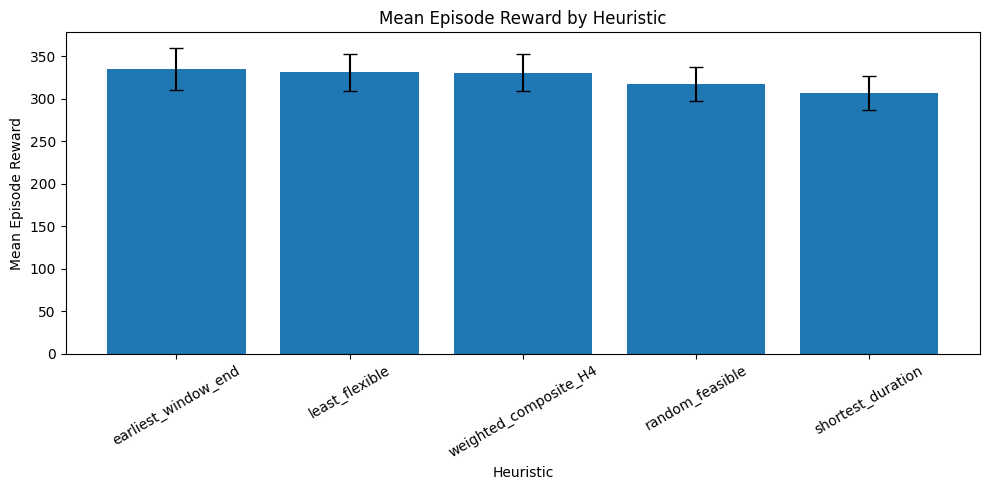

In [58]:

import matplotlib.pyplot as plt

reward_plot_data = baseline_cross_week_summary.sort_values(
    "mean_reward", ascending=False
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    reward_plot_data["method"],
    reward_plot_data["mean_reward"],
    yerr=reward_plot_data["std_reward"].fillna(0),
    capsize=5
)

ax.set_title("Mean Episode Reward by Heuristic")
ax.set_xlabel("Heuristic")
ax.set_ylabel("Mean Episode Reward")
ax.tick_params(axis="x", rotation=30)

fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "mean_episode_reward_by_heuristic.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Plot Mean Scheduled Requests by Heuristic

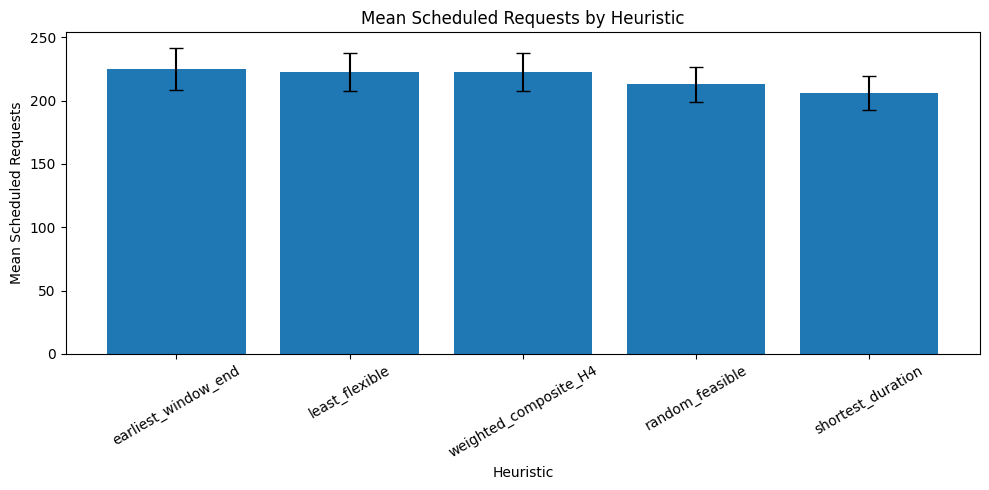

In [59]:

scheduled_plot_data = baseline_cross_week_summary.sort_values(
    "mean_scheduled_requests", ascending=False
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    scheduled_plot_data["method"],
    scheduled_plot_data["mean_scheduled_requests"],
    yerr=scheduled_plot_data["std_scheduled_requests"].fillna(0),
    capsize=5
)

ax.set_title("Mean Scheduled Requests by Heuristic")
ax.set_xlabel("Heuristic")
ax.set_ylabel("Mean Scheduled Requests")
ax.tick_params(axis="x", rotation=30)

fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "mean_scheduled_requests_by_heuristic.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Plot Mean Runtime by Heuristic

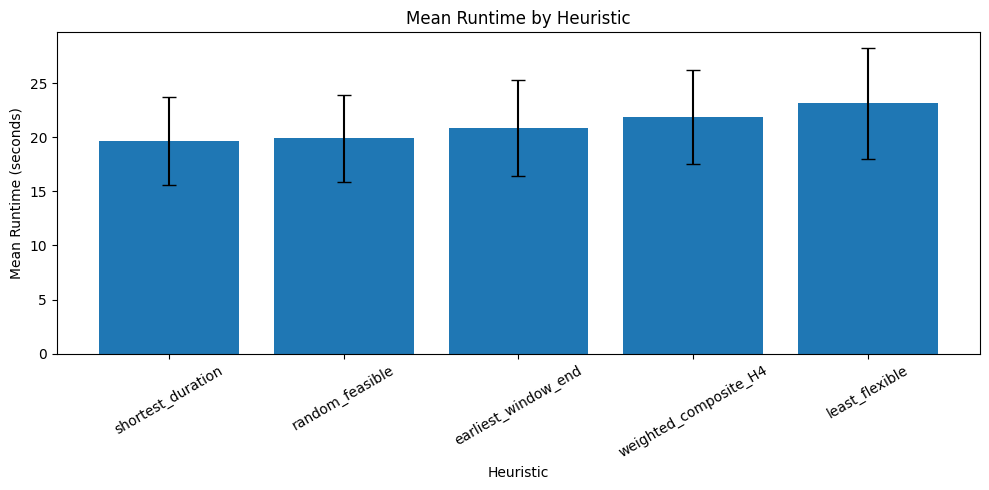

In [60]:

runtime_plot_data = baseline_cross_week_summary.sort_values(
    "mean_runtime_seconds", ascending=True
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    runtime_plot_data["method"],
    runtime_plot_data["mean_runtime_seconds"],
    yerr=runtime_plot_data["std_runtime_seconds"].fillna(0),
    capsize=5
)

ax.set_title("Mean Runtime by Heuristic")
ax.set_xlabel("Heuristic")
ax.set_ylabel("Mean Runtime (seconds)")
ax.tick_params(axis="x", rotation=30)

fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "mean_runtime_by_heuristic.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Plot Episode Reward Across Weeks

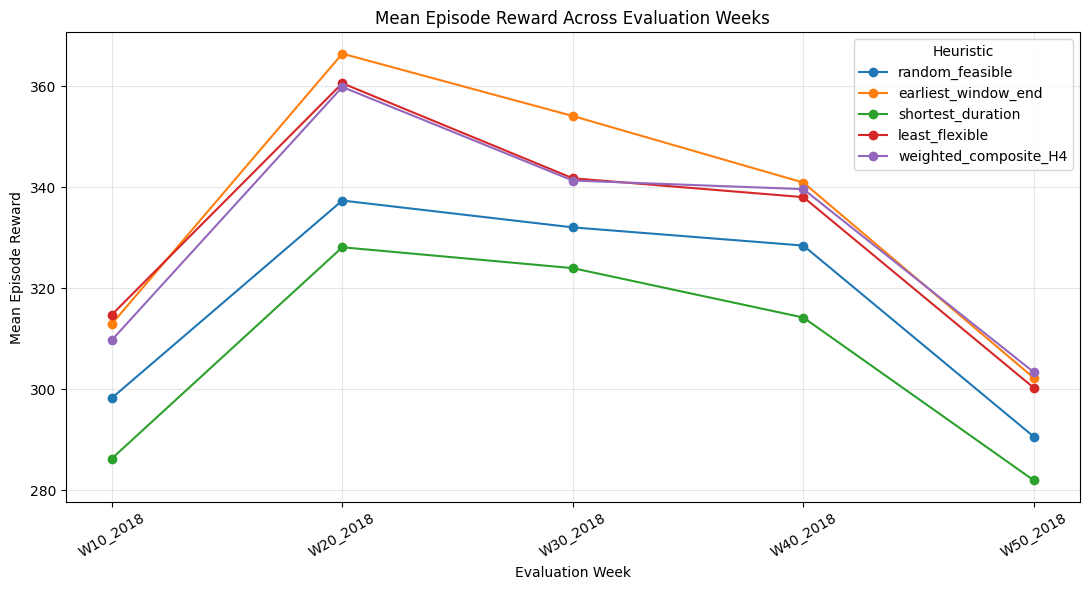

In [61]:

weekly_reward_summary = (
    baseline_cross_week_results
    .groupby(["week_key", "method"], as_index=False)
    .agg(mean_reward=("episode_reward", "mean"))
)

week_order = [
    fold["test_week"]
    for fold in ROBUSTNESS_FOLDS
]

fig, ax = plt.subplots(figsize=(11, 6))

for method in evaluation_methods:
    method_data = (
        weekly_reward_summary[
            weekly_reward_summary["method"] == method
        ]
        .set_index("week_key")
        .reindex(week_order)
    )

    ax.plot(
        week_order,
        method_data["mean_reward"],
        marker="o",
        label=method
    )

ax.set_title("Mean Episode Reward Across Evaluation Weeks")
ax.set_xlabel("Evaluation Week")
ax.set_ylabel("Mean Episode Reward")
ax.legend(title="Heuristic")
ax.grid(alpha=0.3)
ax.tick_params(axis="x", rotation=30)

fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "mean_episode_reward_across_weeks.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Plot Mean Duration Fulfillment by Heuristic

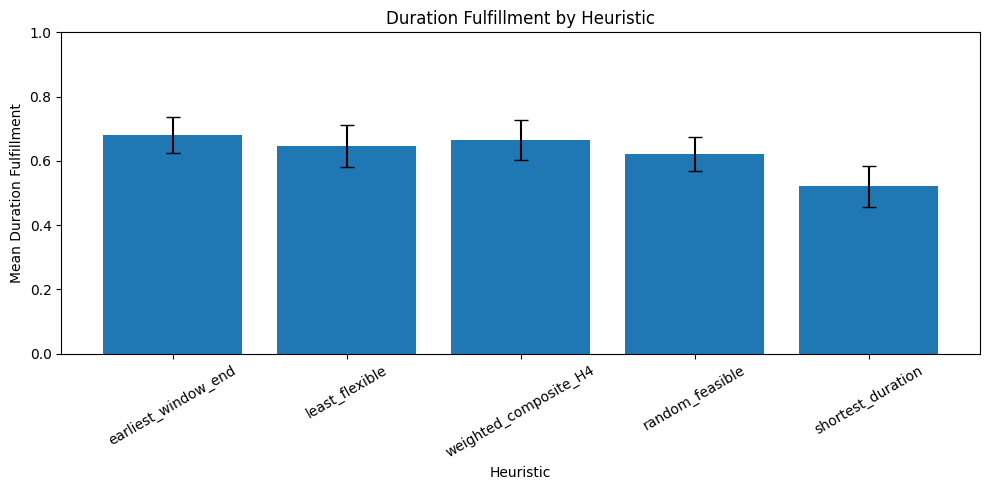

Figure saved: /content/drive/MyDrive/BEE/member1_baselines/baseline_figures/duration_fulfillment_by_heuristic.png


In [74]:
fulfillment_summary = baseline_cross_week_results.groupby("method", as_index=False)["duration_fulfillment"].agg(["mean", "std"]).reset_index()

method_order = baseline_cross_week_summary["method"].tolist()
fulfillment_summary = fulfillment_summary.set_index("method").loc[method_order].reset_index()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(fulfillment_summary["method"], fulfillment_summary["mean"], yerr=fulfillment_summary["std"], capsize=5)
ax.set_title("Duration Fulfillment by Heuristic")
ax.set_xlabel("Heuristic")
ax.set_ylabel("Mean Duration Fulfillment")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()

figure_path = FIGURE_DIR / "duration_fulfillment_by_heuristic.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

assert figure_path.is_file()
print("Figure saved:", figure_path)

Plot Minimum Satisfaction by Heuristic

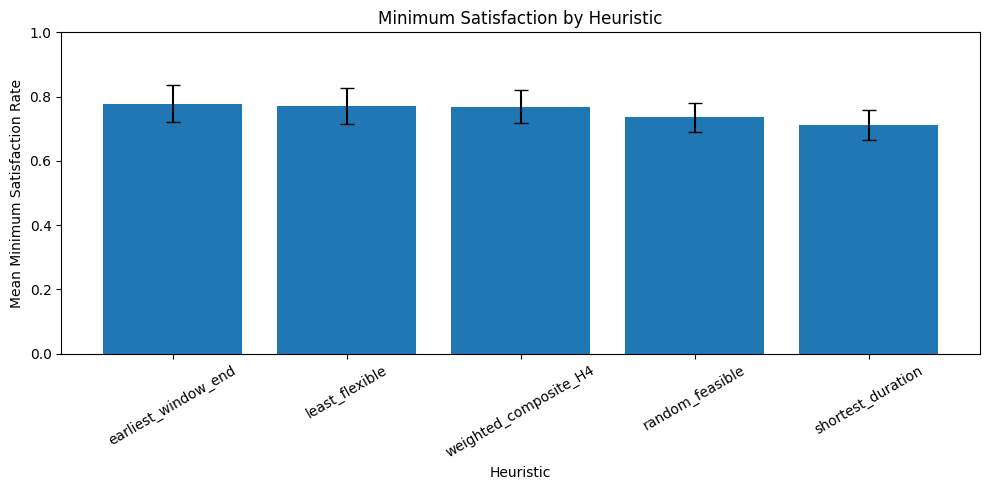

Figure saved: /content/drive/MyDrive/BEE/member1_baselines/baseline_figures/minimum_satisfaction_by_heuristic.png


In [75]:
minimum_summary = baseline_cross_week_results.groupby("method")["minimum_satisfaction_rate"].agg(["mean", "std"]).loc[method_order].reset_index()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(minimum_summary["method"], minimum_summary["mean"], yerr=minimum_summary["std"], capsize=5)
ax.set_title("Minimum Satisfaction by Heuristic")
ax.set_xlabel("Heuristic")
ax.set_ylabel("Mean Minimum Satisfaction Rate")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()

figure_path = FIGURE_DIR / "minimum_satisfaction_by_heuristic.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

assert figure_path.is_file()
print("Figure saved:", figure_path)

Plot Full Satisfaction by Heuristic

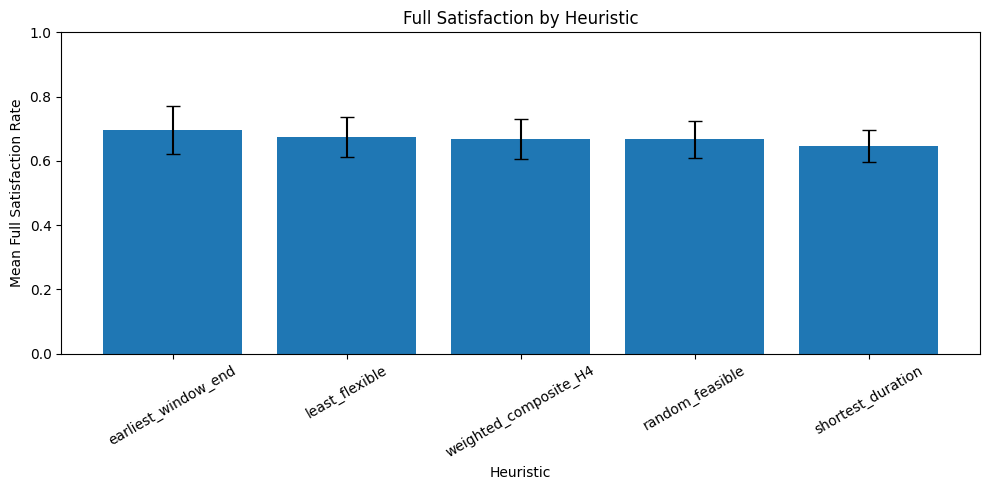

Figure saved: /content/drive/MyDrive/BEE/member1_baselines/baseline_figures/full_satisfaction_by_heuristic.png


In [76]:
full_summary = baseline_cross_week_results.groupby("method")["full_satisfaction_rate"].agg(["mean", "std"]).loc[method_order].reset_index()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(full_summary["method"], full_summary["mean"], yerr=full_summary["std"], capsize=5)
ax.set_title("Full Satisfaction by Heuristic")
ax.set_xlabel("Heuristic")
ax.set_ylabel("Mean Full Satisfaction Rate")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()

figure_path = FIGURE_DIR / "full_satisfaction_by_heuristic.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

assert figure_path.is_file()
print("Figure saved:", figure_path)

Plot Mission Fairness by Heuristic

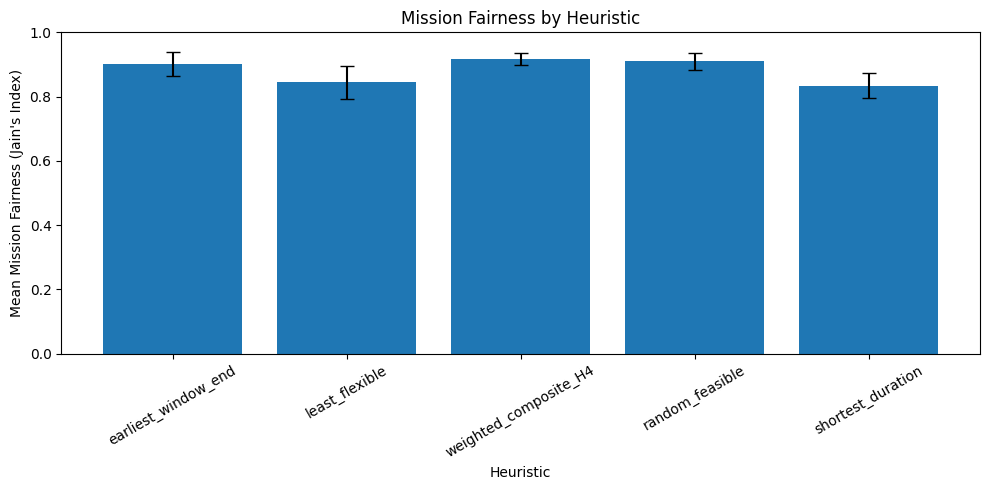

Figure saved: /content/drive/MyDrive/BEE/member1_baselines/baseline_figures/mission_fairness_by_heuristic.png


In [77]:
fairness_summary = baseline_cross_week_results.groupby("method")["mission_fairness"].agg(["mean", "std"]).loc[method_order].reset_index()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(fairness_summary["method"], fairness_summary["mean"], yerr=fairness_summary["std"], capsize=5)
ax.set_title("Mission Fairness by Heuristic")
ax.set_xlabel("Heuristic")
ax.set_ylabel("Mean Mission Fairness (Jain's Index)")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()

figure_path = FIGURE_DIR / "mission_fairness_by_heuristic.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

assert figure_path.is_file()
print("Figure saved:", figure_path)

Table A: Heuristic Definitions

In [78]:
heuristic_definitions = pd.DataFrame([
    {"Method": "Random Feasible", "Selection Rule": "Randomly select a feasible request", "Expected Strength": "Simple exploration baseline", "Expected Limitation": "No scheduling priority"},
    {"Method": "Earliest Window End", "Selection Rule": "Prioritize the earliest ending feasible window", "Expected Strength": "Reduces urgency-related missed opportunities", "Expected Limitation": "Does not directly optimize fairness"},
    {"Method": "Shortest Duration", "Selection Rule": "Prioritize the shortest requested duration", "Expected Strength": "Can fit more short requests", "Expected Limitation": "May neglect longer requests"},
    {"Method": "Least Flexible", "Selection Rule": "Prioritize requests with fewer placement opportunities", "Expected Strength": "Protects constrained requests", "Expected Limitation": "May reduce overall duration fulfillment"},
    {"Method": "Weighted Composite H4", "Selection Rule": "Weighted scarcity, urgency, and unmet mission demand", "Expected Strength": "Balances scheduling priorities and fairness", "Expected Limitation": "Sensitive to selected weights"}
])

assert len(heuristic_definitions) == 5
display(heuristic_definitions)

,Method,Selection Rule,Expected Strength,Expected Limitation
0,Random Feasible,Randomly select a feasible request,Simple exploration baseline,No scheduling priority
1,Earliest Window End,Prioritize the earliest ending feasible window,Reduces urgency-related missed opportunities,Does not directly optimize fairness
2,Shortest Duration,Prioritize the shortest requested duration,Can fit more short requests,May neglect longer requests
3,Least Flexible,Prioritize requests with fewer placement oppor...,Protects constrained requests,May reduce overall duration fulfillment
4,Weighted Composite H4,"Weighted scarcity, urgency, and unmet mission ...",Balances scheduling priorities and fairness,Sensitive to selected weights


Table B: Validation Configuration Results

In [90]:
validation_records = []

for config in ["H1", "H2", "H3", "H4"]:
    checkpoint_path = CHECKPOINT_DIR / f"weighted_composite_{config}_W40_2018_seed1001.json"
    with open(checkpoint_path, "r", encoding="utf-8") as file:
        record = json.load(file)

    schedule = pd.read_parquet(record["schedule_file"])
    requests = request_table.loc[request_table["week_key"] == "W40_2018"].copy()
    allocated = schedule.groupby("track_id")["allocated_seconds"].sum()
    requests["allocated_seconds"] = requests["track_id"].map(allocated).fillna(0.0)

    mission_totals = requests.groupby("subject").agg(requested=("duration_seconds", "sum"), allocated=("allocated_seconds", "sum"))
    mission_ratios = (mission_totals["allocated"] / mission_totals["requested"]).to_numpy(dtype=float)
    fairness = mission_ratios.sum() ** 2 / (len(mission_ratios) * np.square(mission_ratios).sum()) if np.square(mission_ratios).sum() > 0 else 0.0

    validation_records.append({
        "Configuration": config,
        "Fulfillment": requests["allocated_seconds"].sum() / requests["duration_seconds"].sum(),
        "Minimum Satisfaction": (requests["allocated_seconds"] >= requests["minimum_duration_seconds"]).mean(),
        "Full Satisfaction": (requests["allocated_seconds"] >= requests["duration_seconds"]).mean(),
        "Fairness": fairness,
        "Runtime": record["runtime_seconds"]
    })

table_b = pd.DataFrame(validation_records)

assert len(table_b) == 4
assert table_b["Configuration"].tolist() == ["H1", "H2", "H3", "H4"]
assert table_b[["Fulfillment", "Minimum Satisfaction", "Full Satisfaction", "Fairness"]].apply(lambda column: column.between(0, 1).all()).all()

display(table_b.round(3))

,Configuration,Fulfillment,Minimum Satisfaction,Full Satisfaction,Fairness,Runtime
0,H1,0.531,0.682,0.547,0.870,22.119
1,H2,0.517,0.679,0.562,0.849,24.224
2,H3,0.533,0.679,0.541,0.883,22.370
3,H4,0.571,0.694,0.547,0.893,23.246


Table C: Cross-Week Heuristic Results

In [91]:
table_c = baseline_cross_week_results.groupby("method", as_index=False).agg(
    fulfillment_mean=("duration_fulfillment", "mean"),
    fulfillment_std=("duration_fulfillment", "std"),
    minimum_satisfaction=("minimum_satisfaction_rate", "mean"),
    full_satisfaction=("full_satisfaction_rate", "mean"),
    fairness=("mission_fairness", "mean"),
    runtime=("runtime_seconds", "mean"),
    violations=("total_violations", "sum")
)

table_c.columns = ["Method", "Fulfillment Mean", "Fulfillment Std", "Minimum Satisfaction", "Full Satisfaction", "Fairness", "Runtime", "Violations"]

assert len(table_c) == 5
assert table_c["Violations"].eq(0).all()

display(table_c.round(3))

,Method,Fulfillment Mean,Fulfillment Std,Minimum Satisfaction,Full Satisfaction,Fairness,Runtime,Violations
0,earliest_window_end,0.680,0.056,0.779,0.696,0.902,20.830,0
1,least_flexible,0.647,0.065,0.770,0.674,0.845,23.137,0
2,random_feasible,0.622,0.052,0.736,0.667,0.909,19.883,0
3,shortest_duration,0.521,0.063,0.712,0.646,0.835,19.619,0
4,weighted_composite_H4,0.665,0.061,0.769,0.667,0.917,21.874,0


Build Final Heuristic Comparison Table

In [63]:
comparison_columns = [
    "method", "experiments", "mean_reward", "std_reward",
    "mean_scheduled_requests", "std_scheduled_requests",
    "mean_allocated_hours", "mean_duration_fulfillment",
    "mean_minimum_satisfaction_rate", "mean_full_satisfaction_rate",
    "mean_unmet_hours", "mean_mission_fairness",
    "mean_runtime_seconds", "std_runtime_seconds", "total_violations"
]

baseline_comparison_table = baseline_cross_week_summary[comparison_columns].copy().sort_values("mean_reward", ascending=False).reset_index(drop=True)

assert set(baseline_comparison_table["method"]) == set(evaluation_methods)
assert baseline_comparison_table["experiments"].eq(25).all()
assert baseline_comparison_table["total_violations"].eq(0).all()

display(baseline_comparison_table.round(3))


,method,experiments,mean_reward,std_reward,mean_scheduled_requests,std_scheduled_requests,mean_allocated_hours,mean_duration_fulfillment,mean_minimum_satisfaction_rate,mean_full_satisfaction_rate,mean_unmet_hours,mean_mission_fairness,mean_runtime_seconds,std_runtime_seconds,total_violations
0,earliest_window_end,25,335.314,24.856,225.28,16.620,956.890,0.680,0.779,0.696,461.290,0.902,20.830,4.427,0
1,least_flexible,25,331.076,21.756,222.64,14.807,908.984,0.647,0.770,0.674,509.196,0.845,23.137,5.130,0
2,weighted_composite_H4,25,330.769,21.568,222.56,14.771,935.206,0.665,0.769,0.667,482.974,0.917,21.874,4.362,0
3,random_feasible,25,317.334,19.910,212.92,13.641,875.558,0.622,0.736,0.667,542.622,0.909,19.883,4.054,0
4,shortest_duration,25,306.892,19.702,206.04,13.489,731.806,0.521,0.712,0.646,686.374,0.835,19.619,4.070,0


#Section 12: Interpretation

Interpret Cross-Week Baseline Performance

In [64]:

assert len(baseline_cross_week_results) == 125
assert baseline_cross_week_summary["experiments"].eq(25).all()

best_method = baseline_cross_week_summary.iloc[0]

print("Best method by mean episode reward:", best_method["method"])
print("Mean episode reward:", round(best_method["mean_reward"], 3))
print("Mean scheduled requests:", round(best_method["mean_scheduled_requests"], 3))
print("Mean runtime (seconds):", round(best_method["mean_runtime_seconds"], 3))
print("Total constraint violations:", int(best_method["total_violations"]))

print("\nAll methods ranked by mean episode reward:")
display(
    baseline_cross_week_summary[
        [
            "method",
            "mean_reward",
            "std_reward",
            "mean_scheduled_requests",
            "mean_runtime_seconds",
            "total_violations"
        ]
    ].round(3)
)


Best method by mean episode reward: earliest_window_end
Mean episode reward: 335.314
Mean scheduled requests: 225.28
Mean runtime (seconds): 20.83
Total constraint violations: 0

All methods ranked by mean episode reward:


,method,mean_reward,std_reward,mean_scheduled_requests,mean_runtime_seconds,total_violations
0,earliest_window_end,335.314,24.856,225.28,20.830,0
1,least_flexible,331.076,21.756,222.64,23.137,0
2,weighted_composite_H4,330.769,21.568,222.56,21.874,0
3,random_feasible,317.334,19.910,212.92,19.883,0
4,shortest_duration,306.892,19.702,206.04,19.619,0


Analyze Performance Stability Across Weeks

In [65]:

assert len(baseline_cross_week_results) == 125

weekly_performance = (
    baseline_cross_week_results
    .groupby(["method", "week_key"], as_index=False)
    .agg(
        mean_reward=("episode_reward", "mean"),
        std_reward=("episode_reward", "std")
    )
)

performance_stability = (
    weekly_performance
    .groupby("method", as_index=False)
    .agg(
        mean_weekly_reward=("mean_reward", "mean"),
        std_across_weeks=("mean_reward", "std"),
        min_weekly_reward=("mean_reward", "min"),
        max_weekly_reward=("mean_reward", "max")
    )
    .sort_values("std_across_weeks")
    .reset_index(drop=True)
)

print("Performance stability across evaluation weeks:")
display(performance_stability.round(3))

weekly_winners = (
    weekly_performance
    .sort_values(
        ["week_key", "mean_reward"],
        ascending=[True, False]
    )
    .groupby("week_key", as_index=False)
    .first()
)

print("\nHighest-reward method in each evaluation week:")
display(
    weekly_winners[
        ["week_key", "method", "mean_reward"]
    ].round(3)
)


Performance stability across evaluation weeks:


,method,mean_weekly_reward,std_across_weeks,min_weekly_reward,max_weekly_reward
0,random_feasible,317.334,21.335,290.581,337.357
1,shortest_duration,306.892,21.468,281.934,328.104
2,weighted_composite_H4,330.769,23.610,303.356,359.843
3,least_flexible,331.076,23.718,300.259,360.587
4,earliest_window_end,335.314,27.157,302.219,366.437



Highest-reward method in each evaluation week:


,week_key,method,mean_reward
0,W10_2018,least_flexible,314.739
1,W20_2018,earliest_window_end,366.437
2,W30_2018,earliest_window_end,354.095
3,W40_2018,earliest_window_end,340.913
4,W50_2018,weighted_composite_H4,303.356


Analyze Constraint Violations and Feasibility

In [66]:

assert len(baseline_cross_week_results) == 125

feasibility_summary = (
    baseline_cross_week_results
    .groupby("method", as_index=False)
    .agg(
        experiments=("seed", "count"),
        total_violations=("total_violations", "sum"),
        max_violations=("total_violations", "max"),
        feasible_experiments=(
            "total_violations",
            lambda values: int((values == 0).sum())
        )
    )
)

feasibility_summary["feasibility_rate"] = (
    feasibility_summary["feasible_experiments"]
    / feasibility_summary["experiments"]
)

assert feasibility_summary["experiments"].eq(25).all()
assert feasibility_summary["total_violations"].eq(0).all()

print("Constraint validation and feasibility summary:")
display(feasibility_summary)

print("\nAll completed evaluation schedules passed independent validation.")

Constraint validation and feasibility summary:


,method,experiments,total_violations,max_violations,feasible_experiments,feasibility_rate
0,earliest_window_end,25,0,0,25,1.0
1,least_flexible,25,0,0,25,1.0
2,random_feasible,25,0,0,25,1.0
3,shortest_duration,25,0,0,25,1.0
4,weighted_composite_H4,25,0,0,25,1.0



All completed evaluation schedules passed independent validation.


Generate Baseline Report Section

In [92]:
summary = baseline_cross_week_summary
results = baseline_cross_week_results

assert len(results) == 125
assert summary["experiments"].eq(25).all()
assert results["total_violations"].eq(0).all()
assert frozen_configuration["selected_configuration"] == "H4"
assert len(heuristic_definitions) == 5
assert len(table_b) == 4
assert len(table_c) == 5

best = summary.loc[summary["mean_reward"].idxmax()]
fairest = summary.loc[summary["mean_mission_fairness"].idxmax()]
fastest = summary.loc[summary["mean_runtime_seconds"].idxmin()]
lowest_fulfillment = summary.loc[summary["mean_duration_fulfillment"].idxmin()]
weekly = results.groupby(["week_key", "method"], as_index=False)["episode_reward"].mean()
weekly_winners = weekly.loc[weekly.groupby("week_key")["episode_reward"].idxmax()].sort_values("week_key")
stability = weekly.groupby("method")["episode_reward"].agg(["std", "min", "max"]).reset_index()
most_stable = stability.loc[stability["std"].idxmin()]

h4 = summary.loc[summary["method"] == "weighted_composite_H4"].iloc[0]
least_flexible = summary.loc[summary["method"] == "least_flexible"].iloc[0]

report = f"""# Baseline Heuristics: Experimental Evaluation

## 1. Methodology
Five scheduling heuristics were evaluated: Random Feasible, Earliest Window End, Shortest Duration, Least Flexible, and Weighted Composite (H4).

The Weighted Composite H4 configuration was selected on W40_2018 using seed 1001, based on the highest episode reward among four predefined configurations (H1–H4). The selected weights were a = 0.50, b = 0.30, c = 0.20, and d = 0.00. This configuration remained frozen during cross-week evaluation.

The cross-week evaluation covered five weeks (W10, W20, W30, W40, and W50 of 2018), with five evaluation seeds per week. Each heuristic completed 25 experiments, producing {len(results)} experiments in total. All methods used the same weeks, seeds, and scheduling constraints.

W40 was also used for H4 configuration selection, so its evaluation results are not fully independent of configuration tuning. W50 was not used for configuration selection.

### Table A: Heuristic Definitions
{heuristic_definitions.to_markdown(index=False)}

### Table B: Validation Configuration Results
{table_b.round(3).to_markdown(index=False)}

Table B reports configuration-selection results on W40_2018 with seed 1001. Runtime values are measured in seconds using the same evaluation implementation.

## 2. Evaluation Metrics
The evaluation includes episode reward, scheduled requests, allocated hours, duration fulfillment, minimum satisfaction rate, full satisfaction rate, unmet hours, mission fairness, runtime, and constraint violations.

Duration fulfillment is the ratio of total allocated to total requested communication time. Minimum and full satisfaction rates represent the proportions of all requests meeting their minimum and full requested durations. Unmet hours represent requested communication time remaining unallocated. Mission fairness uses Jain's fairness index over mission-level allocated-to-requested duration ratios. Unscheduled requests are included in these calculations.

## 3. Cross-Week Results

### Table C: Cross-Week Heuristic Results
{table_c.round(3).to_markdown(index=False)}

### Extended Heuristic Comparison
{baseline_comparison_table.round(3).to_markdown(index=False)}

The highest mean episode reward was achieved by **{best['method']}** ({best['mean_reward']:.3f}), with {best['mean_scheduled_requests']:.2f} scheduled requests and {best['mean_allocated_hours']:.2f} allocated hours per experiment on average.

The highest mean mission fairness was achieved by **{fairest['method']}** ({fairest['mean_mission_fairness']:.3f}). The lowest mean runtime was recorded by **{fastest['method']}** ({fastest['mean_runtime_seconds']:.3f} seconds).

The lowest duration fulfillment was observed for **{lowest_fulfillment['method']}** ({lowest_fulfillment['mean_duration_fulfillment']:.3f}).

## 4. Weighted Composite H4 vs. Least Flexible
Weighted Composite H4 achieved mean duration fulfillment of {h4['mean_duration_fulfillment']:.3f}, compared with {least_flexible['mean_duration_fulfillment']:.3f} for Least Flexible.

H4 achieved mean mission fairness of {h4['mean_mission_fairness']:.3f}, compared with {least_flexible['mean_mission_fairness']:.3f} for Least Flexible.

Their mean episode rewards were {h4['mean_reward']:.3f} and {least_flexible['mean_reward']:.3f}, respectively. Their mean runtimes were {h4['mean_runtime_seconds']:.3f} and {least_flexible['mean_runtime_seconds']:.3f} seconds.

These results indicate that H4 improved duration fulfillment and mission fairness relative to Least Flexible, but did not achieve a higher mean episode reward.

## 5. Cross-Week Stability
The highest-reward heuristic in each evaluation week was:

{weekly_winners.round(3).to_markdown(index=False)}

The lowest standard deviation across weekly mean rewards was observed for **{most_stable['method']}** ({most_stable['std']:.3f}).

Fulfillment variability across the 25 experiments per method is reported in Table C. Performance rankings varied between weeks, so the heuristic with the highest overall mean reward was not necessarily the most stable.

## 6. Constraint Feasibility
All {len(results)} evaluation schedules passed independent constraint validation. The total number of recorded violations was {int(results['total_violations'].sum())}, corresponding to an observed feasibility rate of 100%.

## 7. Discussion and Limitations
Earliest Window End achieved the highest average episode reward, scheduled request count, allocated communication hours, and duration fulfillment. Weighted Composite H4 achieved the highest average mission fairness.

The results partially support the expectation that combining scarcity, urgency, and mission unmet demand can improve scheduling balance. H4 improved fairness relative to the other heuristics, but did not outperform Earliest Window End in overall reward or duration fulfillment.

Shortest Duration performed poorest in duration fulfillment, illustrating that prioritizing short requests does not necessarily maximize allocated communication time.

Runtime differences were relatively small across the five final evaluation methods, and all methods produced feasible schedules.

The evaluation is limited to five weeks and five seeds per week. H4 was selected using W40, which was also included in cross-week evaluation. The reported differences are descriptive and do not establish statistical significance or generalization to unseen scheduling distributions.

## 8. Recommended Next Step
Use Earliest Window End as the strongest observed baseline for reward and duration fulfillment, and Weighted Composite H4 as the fairness-oriented baseline when evaluating reinforcement learning schedulers.

Future comparisons should use the same scheduling constraints, held-out evaluation conditions, validation procedure, and metrics.
"""

report_path = OUTPUT_ROOT / "baseline_report_section.md"
report_path.write_text(report, encoding="utf-8")

assert report_path.exists()
assert report_path.read_text(encoding="utf-8") == report

print("Report saved:", report_path)
print("Report length:", len(report), "characters")
print("Report verification passed.")

Report saved: /content/drive/MyDrive/BEE/member1_baselines/baseline_report_section.md
Report length: 10932 characters
Report verification passed.


#Section 13: Save All Outputs

Export Final Baseline Results

In [93]:
validation_path = OUTPUT_ROOT / "baseline_validation_results.csv"
results_path = OUTPUT_ROOT / "baseline_cross_week_results.csv"
summary_path = OUTPUT_ROOT / "baseline_cross_week_summary.csv"

validation_export = baseline_cross_week_results[["method", "week_key", "seed", "total_violations"]].copy()

assert len(validation_export) == 125
assert len(baseline_cross_week_results) == 125
assert len(baseline_cross_week_summary) == 5
assert validation_export["total_violations"].eq(0).all()

validation_export.to_csv(validation_path, index=False)
baseline_cross_week_results.to_csv(results_path, index=False)
baseline_cross_week_summary.to_csv(summary_path, index=False)

assert len(pd.read_csv(validation_path)) == 125
assert len(pd.read_csv(results_path)) == 125
assert len(pd.read_csv(summary_path)) == 5

print("Validation results saved:", validation_path)
print("Cross-week results saved:", results_path)
print("Cross-week summary saved:", summary_path)
print("All three CSV files saved and verified.")

Validation results saved: /content/drive/MyDrive/BEE/member1_baselines/baseline_validation_results.csv
Cross-week results saved: /content/drive/MyDrive/BEE/member1_baselines/baseline_cross_week_results.csv
Cross-week summary saved: /content/drive/MyDrive/BEE/member1_baselines/baseline_cross_week_summary.csv
All three CSV files saved and verified.


Verify Final Baseline Deliverables

In [96]:
required_files = [
    OUTPUT_ROOT / "baseline_configuration.json",
    OUTPUT_ROOT / "baseline_validation_results.csv",
    OUTPUT_ROOT / "baseline_cross_week_results.csv",
    OUTPUT_ROOT / "baseline_cross_week_summary.csv",
    OUTPUT_ROOT / "baseline_report_section.md"
]

required_directories = [
    OUTPUT_ROOT / "baseline_schedules",
    OUTPUT_ROOT / "baseline_figures"
]

for path in required_files:
    assert path.is_file(), f"Missing file: {path.name}"
    print("Verified file:", path.name)

for path in required_directories:
    assert path.is_dir(), f"Missing directory: {path.name}"
    print("Verified directory:", path.name)

expected_paths = set(baseline_cross_week_results["schedule_file"].astype(str))
actual_paths = {str(path) for path in SCHEDULE_DIR.glob("*.parquet")}

assert len(expected_paths) == 125
assert expected_paths.issubset(actual_paths)

required_figures = [
    "duration_fulfillment_by_heuristic.png",
    "minimum_satisfaction_by_heuristic.png",
    "full_satisfaction_by_heuristic.png",
    "mission_fairness_by_heuristic.png",
    "mean_runtime_by_heuristic.png",
    "mean_episode_reward_across_weeks.png"
]

for filename in required_figures:
    assert (FIGURE_DIR / filename).is_file(), f"Missing figure: {filename}"
    print("Verified figure:", filename)

assert len(heuristic_definitions) == 5
assert len(table_b) == 4
assert len(table_c) == 5
assert len(baseline_cross_week_results) == 125
assert baseline_cross_week_results["total_violations"].eq(0).all()

print("Verified evaluation schedules:", len(expected_paths))
print("Verified required figures:", len(required_figures))
print("Verified total figures:", len(list(FIGURE_DIR.glob("*.png"))))
print("Verified tables: A, B, C")
print("All baseline deliverables verified.")

Verified file: baseline_configuration.json
Verified file: baseline_validation_results.csv
Verified file: baseline_cross_week_results.csv
Verified file: baseline_cross_week_summary.csv
Verified file: baseline_report_section.md
Verified directory: baseline_schedules
Verified directory: baseline_figures
Verified figure: duration_fulfillment_by_heuristic.png
Verified figure: minimum_satisfaction_by_heuristic.png
Verified figure: full_satisfaction_by_heuristic.png
Verified figure: mission_fairness_by_heuristic.png
Verified figure: mean_runtime_by_heuristic.png
Verified figure: mean_episode_reward_across_weeks.png
Verified evaluation schedules: 125
Verified required figures: 6
Verified total figures: 8
Verified tables: A, B, C
All baseline deliverables verified.
